In [217]:
# !pip list
# !pip install torch torchvision

In [218]:
# !pip install numpy
# !pip install matplotlib
# !pip install scikit-learn
# !pip install scikit-image

In [219]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity

# Pilih device: CUDA (Colab GPU) -> MPS (Apple Silicon) -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.15.0 | device: mps


In [220]:
# 1. Kunci seed agar hasil selalu konsisten (reproducible)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# 2. Unduh raw dataset via torchvision (60.000 train + 10.000 test bawaan)
train_raw = datasets.FashionMNIST(root="./data", train=True, download=True)
test_raw  = datasets.FashionMNIST(root="./data", train=False, download=True)
# 3. Gabungkan seluruh 70.000 citra, normalisasi [0, 1], dan flatten ke 784
X_all = torch.cat([train_raw.data, test_raw.data], dim=0).numpy().astype(np.float32) / 255.0
X_all = X_all.reshape(-1, 784)  # 28x28 -> 784
y_all = torch.cat([train_raw.targets, test_raw.targets], dim=0).numpy()
# 4. Split Pertama: Ambil 80% Train (56.000) dan 20% Temp (14.000)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)
# 5. Split Kedua: Bagi 20% Temp menjadi 10% Val (7.000) dan 10% Test (7.000)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print(f"Total dataset : {len(X_all)} citra")
print(f"Train set     : {len(X_train)} citra (80%)")
print(f"Val set       : {len(X_val)} citra (10%)")
print(f"Test set      : {len(X_test)} citra (10%)")
# 6. DataLoader: shuffle=True untuk train, shuffle=False untuk val/test
BATCH_SIZE = 256
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    g = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)
train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader   = make_loader(X_val, y_val, shuffle=False)
test_loader  = make_loader(X_test, y_test, shuffle=False)

Total dataset : 70000 citra
Train set     : 56000 citra (80%)
Val set       : 7000 citra (10%)
Test set      : 7000 citra (10%)


In [221]:
@torch.no_grad()
def predict(module, X, batch_size=BATCH_SIZE):
    module.eval()
    outputs = []
    for i in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[i:i + batch_size], dtype=torch.float32, device=device)
        outputs.append(module(xb).cpu())
    return torch.cat(outputs).numpy()

## Tahap 1: MLP Classifier

MLP Classifier dipakai untuk membuktikan bahwa bobot dan fitur laten model klasifikasi tidak dapat langsung dipakai untuk image generation (Bagian 2 tugas). Struktur lapisan ekstraksi fiturnya sengaja dibuat sama dengan encoder Autoencoder.

| Lapisan | Dimensi | Aktivasi |
|---|---|---|
| `dense_1` ($W_1$) | 784 → 256 | ReLU |
| `z_latent` ($W_2$) | 256 → 64 | ReLU |
| `classifier` ($W_3$) | 64 → 10 | logits |

Model dilatih dengan Cross-Entropy Loss untuk memodelkan $P(y \mid x)$:

$$\mathcal{L}_{CE} = -\sum_{c=1}^{10} y_c \log \mathrm{softmax}(f(x))_c$$

- Optimizer: Adam, learning rate $10^{-3}$, batch size 256, 30 epoch.
- Target: akurasi test set minimal 88%.
- Representasi laten $z_{MLP} \in \mathbb{R}^{64}$ diambil dari keluaran `z_latent` (lapisan sebelum klasifikasi akhir).
- Matriks bobot $W_1, W_2, W_3$ disimpan untuk Tahap 2 dan Tahap 3.

In [222]:
LATENT_DIM = 64
EPOCHS = 30

class MLPClassifier(nn.Module):
    """MLP Classifier 784 -> 256 -> 64 -> 10 (output berupa logits)."""
    def __init__(self, latent_dim=LATENT_DIM, num_classes=10):
        super().__init__()
        self.dense_1    = nn.Linear(784, 256)
        self.z_latent   = nn.Linear(256, latent_dim)
        self.classifier = nn.Linear(latent_dim, num_classes)

    def forward(self, x):
        h = F.relu(self.dense_1(x))
        z = F.relu(self.z_latent(h))
        return self.classifier(z)

model = MLPClassifier().to(device)
# ekstrak fitur latenn: encoder berbagi layer (bobot yang sama) dengan classifier
encoder = nn.Sequential(model.dense_1, nn.ReLU(), model.z_latent, nn.ReLU())
print(model)

# CrossEntropyLoss menerima logits (setara SparseCategoricalCrossentropy(from_logits=True))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

@torch.no_grad()
def evaluate_classifier(net, loader):
    net.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = net(xb)
        total_loss += criterion(logits, yb).item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n

history_mlp = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
for epoch in range(EPOCHS):
    model.train()
    run_loss, run_correct, n = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * len(xb)
        run_correct += (logits.argmax(dim=1) == yb).sum().item()
        n += len(xb)
    val_loss, val_acc = evaluate_classifier(model, val_loader)
    history_mlp["loss"].append(run_loss / n)
    history_mlp["accuracy"].append(run_correct / n)
    history_mlp["val_loss"].append(val_loss)
    history_mlp["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - loss: {run_loss / n:.4f} - accuracy: {run_correct / n:.4f}"
          f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

MLPClassifier(
  (dense_1): Linear(in_features=784, out_features=256, bias=True)
  (z_latent): Linear(in_features=256, out_features=64, bias=True)
  (classifier): Linear(in_features=64, out_features=10, bias=True)
)
Epoch 01/30 - loss: 0.6851 - accuracy: 0.7648 - val_loss: 0.4825 - val_accuracy: 0.8274
Epoch 02/30 - loss: 0.4426 - accuracy: 0.8435 - val_loss: 0.4237 - val_accuracy: 0.8501
Epoch 03/30 - loss: 0.3989 - accuracy: 0.8588 - val_loss: 0.3965 - val_accuracy: 0.8554
Epoch 04/30 - loss: 0.3678 - accuracy: 0.8687 - val_loss: 0.3826 - val_accuracy: 0.8574
Epoch 05/30 - loss: 0.3475 - accuracy: 0.8748 - val_loss: 0.3698 - val_accuracy: 0.8704
Epoch 06/30 - loss: 0.3248 - accuracy: 0.8827 - val_loss: 0.3449 - val_accuracy: 0.8744
Epoch 07/30 - loss: 0.3107 - accuracy: 0.8872 - val_loss: 0.3428 - val_accuracy: 0.8761
Epoch 08/30 - loss: 0.2980 - accuracy: 0.8918 - val_loss: 0.3584 - val_accuracy: 0.8707
Epoch 09/30 - loss: 0.2877 - accuracy: 0.8943 - val_loss: 0.3275 - val_accuracy:

In [223]:
test_loss, test_acc = evaluate_classifier(model, test_loader)
print("\n" + "="*40)
print(f"HASIL EVALUASI TEST SET:")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
z_test = predict(encoder, X_test)
print(f"\nBentuk representasi laten z_test : {z_test.shape} (7.000 citra x 64 dimensi)")
# 3. Simpan matriks bobot terlatih W1, W2, W3 (diperlukan untuk Tahap 2 & 3)
# Catatan: nn.Linear menyimpan bobot berukuran (out, in). Bobot ditranspos di sini
# agar mengikuti konvensi (in, out) seperti Keras, sehingga y = x @ W + b.
W1 = model.dense_1.weight.detach().cpu().numpy().T     # Bobot W1: (784, 256)
b1 = model.dense_1.bias.detach().cpu().numpy()
W2 = model.z_latent.weight.detach().cpu().numpy().T    # Bobot W2: (256, 64)
b2 = model.z_latent.bias.detach().cpu().numpy()
W3 = model.classifier.weight.detach().cpu().numpy().T  # Bobot W3: (64, 10)
b3 = model.classifier.bias.detach().cpu().numpy()
print(f"Bentuk matriks bobot W1: {W1.shape}")
print(f"Bentuk matriks bobot W2: {W2.shape}")
print(f"Bentuk matriks bobot W3: {W3.shape}")


HASIL EVALUASI TEST SET:
Test Loss    : 0.3534
Test Accuracy: 89.43%

Bentuk representasi laten z_test : (7000, 64) (7.000 citra x 64 dimensi)
Bentuk matriks bobot W1: (784, 256)
Bentuk matriks bobot W2: (256, 64)
Bentuk matriks bobot W3: (64, 10)


In [224]:
import matplotlib.pyplot as plt
# Definisi fungsi aktivasi
def relu(x):
    return np.maximum(0, x)
def sigmoid(x):
    # Hitung dalam float64 + np.clip untuk mencegah numerical overflow pada np.exp
    x = np.asarray(x, dtype=np.float64)
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))
def hide_axes(ax):
    # Pengganti plt.axis('off') yang tetap menampilkan ylabel (label baris)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
# Label kelas Fashion-MNIST
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

## Tahap 2: Proyeksi Balik Bobot dari Vektor Kelas (Top-Down Weight Transposition)

Vektor one-hot kelas $y_c \in \mathbb{R}^{10}$ diproyeksikan balik ke ruang piksel memakai transpos bobot MLP, tanpa pelatihan tambahan:

$$\hat{z} = \mathrm{ReLU}(W_3^T y_c), \quad \hat{h}_1 = \mathrm{ReLU}(W_2^T \hat{z}), \quad \hat{x} = \mathrm{Sigmoid}(W_1^T \hat{h}_1)$$

Karena $W^T \neq W^{-1}$, hasil yang diharapkan berupa pola bercak kabur (superposisi template bobot), bukan citra pakaian yang utuh.

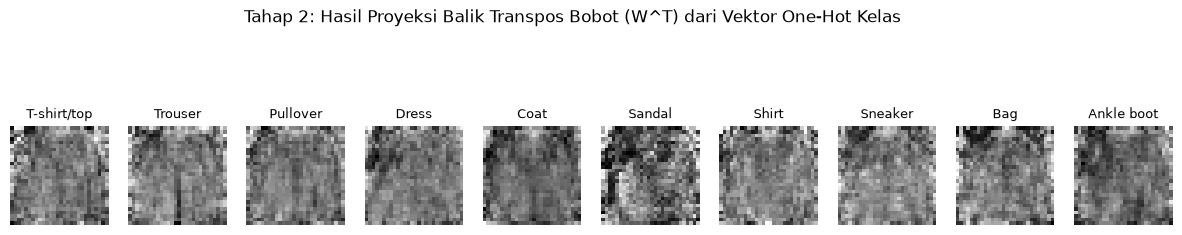

In [225]:
# 1. Buat vektor one-hot untuk ke-10 kelas (10 x 10)
y_onehot = np.eye(10, dtype=np.float32)
# 2. Proyeksi balik berjenjang: y_c (10) -> z_hat (64) -> h1_hat (256) -> x_hat (784)
z_hat  = relu(y_onehot @ W3.T)   # W3.T berukuran (10, 64)
h1_hat = relu(z_hat @ W2.T)      # W2.T berukuran (64, 256)
x_hat  = sigmoid(h1_hat @ W1.T)  # W1.T berukuran (256, 784)
# Visualisasi Tahap 2: 10 Kelas Hasil Proyeksi Balik Transpos W^T
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_hat[i].reshape(28, 28), cmap='gray')
    plt.title(class_names[i], fontsize=9)
    plt.axis('off')
plt.suptitle("Tahap 2: Hasil Proyeksi Balik Transpos Bobot (W^T) dari Vektor One-Hot Kelas", fontsize=12, y=1.05)
plt.show()

## Tahap 3: Proyeksi Balik dari Fitur Laten Citra Uji (Latent Transpose Projection)

Fitur laten $z_{MLP}$ dari 8 citra test diproyeksikan langsung ke ruang piksel:

$$\hat{x} = \mathrm{Sigmoid}\left(W_1^T \, \mathrm{ReLU}(W_2^T z_{MLP})\right)$$

Hasilnya dibandingkan dengan citra asli untuk menunjukkan bahwa bobot maju (forward weights) klasifikasi tidak dapat dibalik menjadi decoder rekonstruktif.

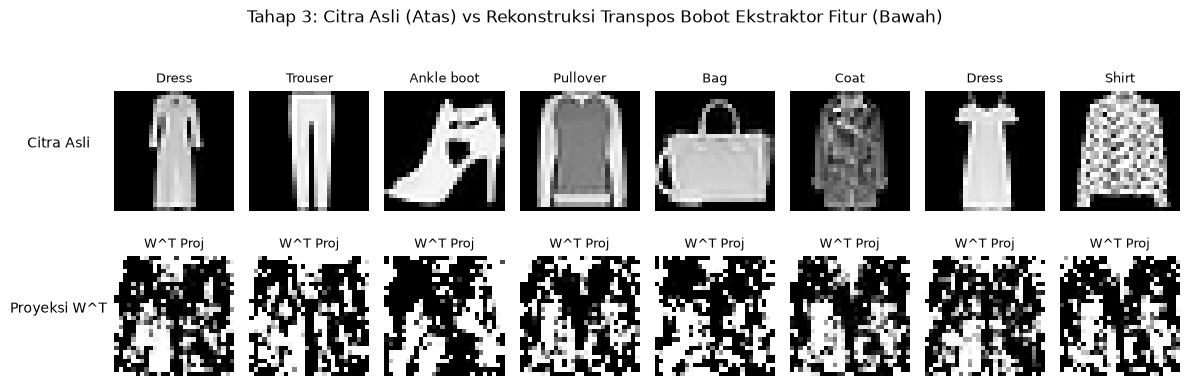

In [226]:
# 1. Ambil 8 sampel citra riil dari Test Set beserta fitur latennya
num_samples = 8
x_real_samples = X_test[:num_samples]
z_real_samples = z_test[:num_samples]
# 2. Proyeksi balik dari z_MLP (64) -> Ruang Piksel (784) via W2^T dan W1^T
# Rumus: x_proj = Sigmoid(W1^T @ ReLU(W2^T @ z_MLP))
h1_proj = relu(z_real_samples @ W2.T)
x_proj  = sigmoid(h1_proj @ W1.T)
# Visualisasi Tahap 3: Perbandingan Citra Asli vs Hasil Transpos Bobot
plt.figure(figsize=(12, 4))
for i in range(num_samples):
    # Baris 1: Citra Asli (Ground Truth)
    ax1 = plt.subplot(2, num_samples, i + 1)
    plt.imshow(x_real_samples[i].reshape(28, 28), cmap='gray')
    plt.title(f"{class_names[y_test[i]]}", fontsize=9)
    hide_axes(ax1)
    if i == 0:
        ax1.set_ylabel("Citra Asli", fontsize=10, rotation=0, labelpad=40)
    # Baris 2: Hasil Proyeksi Balik Transpos (x_hat)
    ax2 = plt.subplot(2, num_samples, num_samples + i + 1)
    plt.imshow(x_proj[i].reshape(28, 28), cmap='gray')
    plt.title("W^T Proj", fontsize=9)
    hide_axes(ax2)
    if i == 0:
        ax2.set_ylabel("Proyeksi W^T", fontsize=10, rotation=0, labelpad=40)
plt.suptitle("Tahap 3: Citra Asli (Atas) vs Rekonstruksi Transpos Bobot Ekstraktor Fitur (Bawah)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## Tahap 4: Frozen Latent Decoder

Seluruh bobot MLP Classifier dibekukan (`requires_grad = False`). Encoder 784 → 256 → 64 memakai bobot yang sama dengan classifier, lalu hanya decoder terpisah yang dilatih untuk merekonstruksi citra dari $z_{MLP}$.

| Bagian | Arsitektur | Status |
|---|---|---|
| Encoder (MLP Classifier) | 784 → 256 → 64, ReLU | dibekukan |
| Decoder | 64 → 256 (ReLU) → 784 (Sigmoid) | dilatih |

Loss rekonstruksi:

$$\mathcal{L}_{MSE} = \frac{1}{784} \lVert x - \hat{x} \rVert_2^2$$

- Optimizer: Adam, learning rate $10^{-3}$, 30 epoch.
- Fungsi `train_autoencoder` di sel ini juga dipakai untuk melatih Vanilla AE.

In [228]:
# 1. bekukan encoder (seluruh bobot MLP Classifier)
for p in model.parameters():
    p.requires_grad = False
encoder.eval()
# 2. Bangun jaringan Decoder MLP terpisah (64 -> 256 -> 784)
torch.manual_seed(SEED)
decoder = nn.Sequential(
    nn.Linear(LATENT_DIM, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid(),
).to(device)
# 3. Rangkai menjadi satu model utuh (End-to-End):
# encoder weights tidak akan diupdate, hanya Decoder yang bobotnya di-update
frozen_autoencoder = nn.Sequential(encoder, decoder)

def count_params(module):
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in module.parameters() if not p.requires_grad)
    return trainable, frozen

print(frozen_autoencoder)
tr, fr = count_params(frozen_autoencoder)
print(f"Trainable params: {tr:,} | Non-trainable params: {fr:,}")

def train_autoencoder(ae, epochs=EPOCHS):
    """Latih autoencoder dengan MSE Loss (target = citra input). Hanya parameter requires_grad=True yang di-update."""
    params = [p for p in ae.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=1e-3)
    mse_loss = nn.MSELoss()
    history = {"loss": [], "val_loss": [], "epoch_time": []}
    for epoch in range(epochs):
        ae.train()
        sync_device()
        t0 = time.perf_counter()
        run_loss, n = 0.0, 0
        for xb, _ in train_loader:
            xb = xb.to(device)
            opt.zero_grad()
            loss = mse_loss(ae(xb), xb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(xb)
            n += len(xb)
        sync_device()
        epoch_time = time.perf_counter() - t0
        ae.eval()
        val_loss, nv = 0.0, 0
        with torch.no_grad():
            for xb, _ in val_loader:
                xb = xb.to(device)
                val_loss += mse_loss(ae(xb), xb).item() * len(xb)
                nv += len(xb)
        history["loss"].append(run_loss / n)
        history["val_loss"].append(val_loss / nv)
        history["epoch_time"].append(epoch_time)
        print(f"Epoch {epoch + 1:02d}/{epochs} - loss: {run_loss / n:.4f} - val_loss: {val_loss / nv:.4f} - {epoch_time:.1f}s")
    return history

history_frozen = train_autoencoder(frozen_autoencoder)
# Pastikan bobot MLP benar-benar tidak berubah selama Tahap 4
assert np.allclose(model.dense_1.weight.detach().cpu().numpy().T, W1)
assert np.allclose(model.z_latent.weight.detach().cpu().numpy().T, W2)

Sequential(
  (0): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
  )
  (1): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Trainable params: 218,128 | Non-trainable params: 217,408
Epoch 01/30 - loss: 0.0420 - val_loss: 0.0290 - 0.9s
Epoch 02/30 - loss: 0.0262 - val_loss: 0.0245 - 0.7s
Epoch 03/30 - loss: 0.0231 - val_loss: 0.0222 - 0.7s
Epoch 04/30 - loss: 0.0215 - val_loss: 0.0211 - 0.8s
Epoch 05/30 - loss: 0.0205 - val_loss: 0.0205 - 1.1s
Epoch 06/30 - loss: 0.0199 - val_loss: 0.0198 - 0.7s
Epoch 07/30 - loss: 0.0193 - val_loss: 0.0194 - 0.7s
Epoch 08/30 - loss: 0.0190 - val_loss: 0.0190 - 0.7s
Epoch 09/30 - loss: 0.0187 - val_loss: 0.0187 - 0.7s
Epoch 10/30 - loss: 0.0183 - val_loss: 0.0185 - 0.8s
Epoch 11/30 - loss: 0.0181 - val_loss: 

## Vanilla Autoencoder

Vanilla AE menjadi pembanding Frozen Latent Decoder dengan dimensi laten yang sama ($z_{AE} \in \mathbb{R}^{64}$). Berbeda dari Tahap 4, encoder dan decoder dilatih bersama sehingga ruang laten dioptimalkan khusus untuk rekonstruksi.

| Bagian | Arsitektur | Aktivasi |
|---|---|---|
| Encoder | 784 → 256 → 64 | ReLU, ReLU |
| Decoder | 64 → 256 → 784 | ReLU, Sigmoid |

Loss:

$$\mathcal{L}_{AE} = \frac{1}{784} \lVert x - g_\phi(f_\theta(x)) \rVert_2^2$$

- Optimizer: Adam, learning rate $10^{-3}$, batch size 256, 30 epoch.
- Ruang laten tidak diregularisasi, sehingga sampling dan interpolasi dapat melewati wilayah kosong (latent voids).

In [229]:
torch.manual_seed(SEED)
vanilla_ae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, LATENT_DIM),
    nn.ReLU(),
).to(device)
vanilla_ae_dec = nn.Sequential(
    nn.Linear(LATENT_DIM, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid(),
).to(device)
vanilla_ae = nn.Sequential(vanilla_ae_enc, vanilla_ae_dec)
print(vanilla_ae)

Sequential(
  (0): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
  )
  (1): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [230]:
history_vanilla = train_autoencoder(vanilla_ae)

Epoch 01/30 - loss: 0.0468 - val_loss: 0.0240 - 0.9s
Epoch 02/30 - loss: 0.0210 - val_loss: 0.0188 - 0.9s
Epoch 03/30 - loss: 0.0177 - val_loss: 0.0168 - 1.0s
Epoch 04/30 - loss: 0.0160 - val_loss: 0.0153 - 1.0s
Epoch 05/30 - loss: 0.0147 - val_loss: 0.0142 - 1.0s
Epoch 06/30 - loss: 0.0138 - val_loss: 0.0135 - 0.8s
Epoch 07/30 - loss: 0.0131 - val_loss: 0.0128 - 0.8s
Epoch 08/30 - loss: 0.0125 - val_loss: 0.0123 - 0.9s
Epoch 09/30 - loss: 0.0120 - val_loss: 0.0118 - 0.9s
Epoch 10/30 - loss: 0.0116 - val_loss: 0.0115 - 0.8s
Epoch 11/30 - loss: 0.0113 - val_loss: 0.0113 - 1.2s
Epoch 12/30 - loss: 0.0110 - val_loss: 0.0109 - 0.8s
Epoch 13/30 - loss: 0.0107 - val_loss: 0.0108 - 0.8s
Epoch 14/30 - loss: 0.0105 - val_loss: 0.0104 - 0.8s
Epoch 15/30 - loss: 0.0102 - val_loss: 0.0102 - 0.8s
Epoch 16/30 - loss: 0.0100 - val_loss: 0.0101 - 0.8s
Epoch 17/30 - loss: 0.0098 - val_loss: 0.0099 - 0.8s
Epoch 18/30 - loss: 0.0097 - val_loss: 0.0097 - 0.8s
Epoch 19/30 - loss: 0.0095 - val_loss: 0.0096 

In [231]:
# 3. Evaluasi Kuantitatif pada Test Set (MSE, PSNR, SSIM)
# Prediksi rekonstruksi test set
X_test_pred_frozen  = predict(frozen_autoencoder, X_test)
X_test_pred_vanilla = predict(vanilla_ae, X_test)
# 1. Hitung Test MSE
mse_frozen  = np.mean((X_test - X_test_pred_frozen) ** 2)
mse_vanilla = np.mean((X_test - X_test_pred_vanilla) ** 2)
# 2. Hitung Test PSNR (Peak Signal-to-Noise Ratio), rata-rata per citra
def mean_psnr(x_true, x_pred, max_val=1.0):
    mse_per_img = np.mean((x_true - x_pred) ** 2, axis=1)
    return np.mean(10.0 * np.log10(max_val ** 2 / mse_per_img))
psnr_frozen  = mean_psnr(X_test, X_test_pred_frozen)
psnr_vanilla = mean_psnr(X_test, X_test_pred_vanilla)
# 3. Hitung Test SSIM (Structural Similarity Index), rata-rata per citra
# Parameter disamakan dengan tf.image.ssim: Gaussian window 11x11, sigma=1.5, K1=0.01, K2=0.03
def mean_ssim(x_true, x_pred):
    scores = [
        structural_similarity(
            a.reshape(28, 28), b.reshape(28, 28),
            data_range=1.0, gaussian_weights=True, sigma=1.5,
            use_sample_covariance=False,
        )
        for a, b in zip(x_true, x_pred)
    ]
    return np.mean(scores)
ssim_frozen  = mean_ssim(X_test, X_test_pred_frozen)
ssim_vanilla = mean_ssim(X_test, X_test_pred_vanilla)
# Tampilkan Tabel Hasil Perbandingan
print("\n" + "="*65)
print(f"{'Metrik':<15} | {'Frozen Latent (MLP)':<20} | {'Vanilla Autoencoder':<20}")
print("="*65)
print(f"{'Test MSE':<15} | {mse_frozen:<20.4f} | {mse_vanilla:<20.4f}  (Lebih kecil lebih baik)")
print(f"{'Test PSNR (dB)':<15} | {psnr_frozen:<20.2f} | {psnr_vanilla:<20.2f}  (Lebih besar lebih baik)")
print(f"{'Test SSIM':<15} | {ssim_frozen:<20.4f} | {ssim_vanilla:<20.4f}  (Mendekati 1 lebih baik)")
print("="*65)
# Latency Vanilla AE (batch 64)
latency_vanilla_ae = measure_latency(lambda: predict(vanilla_ae, X_test[:64]), n_runs=20)
print(f"Vanilla AE latency (batch 64): {latency_vanilla_ae:.3f} ms")
print(f"Vanilla AE training time / epoch: {np.mean(history_vanilla['epoch_time']):.2f} s")



Metrik          | Frozen Latent (MLP)  | Vanilla Autoencoder 
Test MSE        | 0.0163               | 0.0087                (Lebih kecil lebih baik)
Test PSNR (dB)  | 18.65                | 21.57                 (Lebih besar lebih baik)
Test SSIM       | 0.6029               | 0.7385                (Mendekati 1 lebih baik)
Vanilla AE latency (batch 64): 0.846 ms
Vanilla AE training time / epoch: 0.87 s


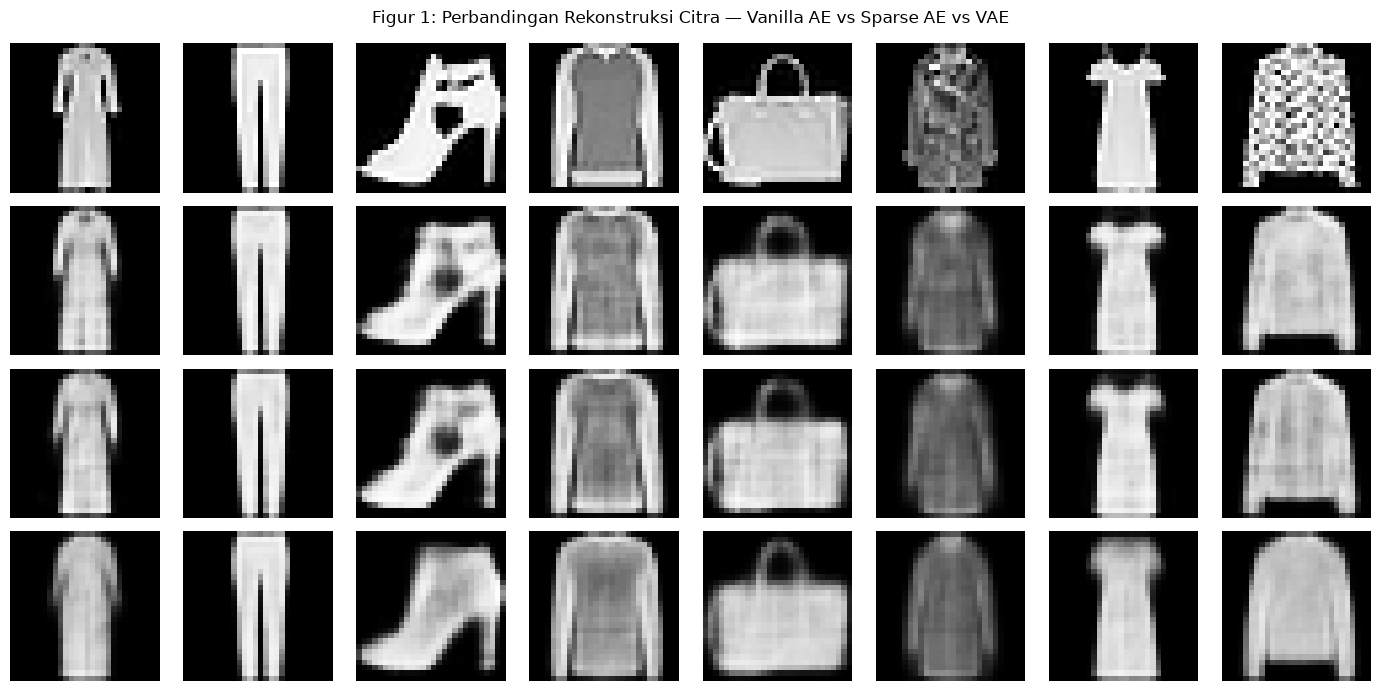

In [233]:
# =============================================================================
# Figur 1: Rekonstruksi Side-by-Side — Asli / Vanilla AE / Sparse AE / VAE
# =============================================================================
n = 8  # jumlah sampel yang ditampilkan
rows = ["Citra Asli", "Vanilla AE", "Sparse AE", "VAE (decoder(μ))"]
preds = [
    X_test[:n],
    X_test_pred_vanilla[:n],
    X_test_pred_sparse[:n],
    X_test_pred_vae[:n],
]

fig, axes = plt.subplots(4, n, figsize=(14, 7))
for r, (row_label, row_data) in enumerate(zip(rows, preds)):
    for c in range(n):
        ax = axes[r, c]
        ax.imshow(row_data[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if c == 0:
            ax.set_ylabel(row_label, fontsize=9, rotation=0, labelpad=55, va="center")

fig.suptitle("Figur 1: Perbandingan Rekonstruksi Citra — Vanilla AE vs Sparse AE vs VAE", fontsize=12)
plt.tight_layout()
plt.show()


## Tahap 5: Uji Sampling Generatif pada Ruang Laten MLP Classifier

Vektor rata-rata $\mu_z$ dan simpangan baku $\sigma_z$ dihitung dari $z_{MLP}$ pada test set. Sampel acak kemudian ditarik dari

$$z_{rand} \sim \mathcal{N}\left(\mu_z, \mathrm{diag}(\sigma_z^2)\right)$$

dan diteruskan ke decoder dari Tahap 4. Ruang laten MLP tidak memiliki regularisasi prior $P(z)$, sehingga sampel yang dihasilkan diharapkan gagal membentuk objek yang utuh.

--- Statistik Ruang Laten MLP Classifier ---
Rata-rata nilai mu_z     : 1.9455
Rata-rata nilai sigma_z  : 2.0359


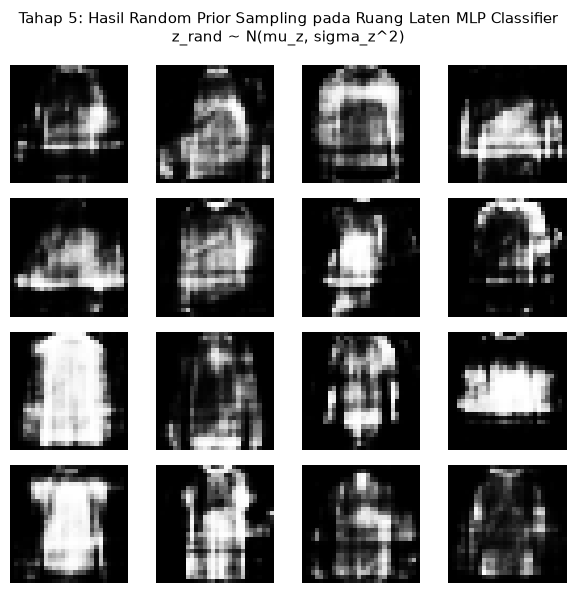

In [234]:
# 1. Ekstrak z_MLP dari z_test yang sudah ada dan Hitung vektor rata-rata (mu_z) dan simpangan baku (sigma_z) sepanjang 64 dimensi

mu_z    = np.mean(z_test, axis=0)  # Bentuk: (64,)
sigma_z = np.std(z_test, axis=0)   # Bentuk: (64,)
print("--- Statistik Ruang Laten MLP Classifier ---")
print(f"Rata-rata nilai mu_z     : {np.mean(mu_z):.4f}")
print(f"Rata-rata nilai sigma_z  : {np.mean(sigma_z):.4f}")

# 2. Tarik sampel acak z_rand ~ N(mu_z, diag(sigma_z^2))
num_gen_samples = 16
np.random.seed(42)  # Seed tetap agar hasil reproducible
z_rand = np.random.normal(loc=mu_z, scale=sigma_z, size=(num_gen_samples, 64))

# 3. Teruskan z_rand ke Decoder dari Tahap 4
x_sampled = predict(decoder, z_rand.astype(np.float32))

# 4. Visualisasi Hasil Sampling (Grid 4x4)
plt.figure(figsize=(6, 6))
for i in range(num_gen_samples):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_sampled[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.suptitle("Tahap 5: Hasil Random Prior Sampling pada Ruang Laten MLP Classifier\nz_rand ~ N(mu_z, sigma_z^2)", fontsize=11, y=0.98)
plt.tight_layout()
plt.show()

## Sparse Autoencoder

Arsitektur Sparse AE sama dengan Vanilla AE. Perbedaannya ada pada penalti L1 terhadap representasi laten $z$, yang mendorong sebagian besar neuron laten bernilai nol untuk tiap citra.

| Bagian | Arsitektur | Aktivasi |
|---|---|---|
| Encoder | 784 → 256 → 64 | ReLU, ReLU |
| Decoder | 64 → 256 → 784 | ReLU, Sigmoid |

Loss:

$$\mathcal{L}_{Sparse} = \mathcal{L}_{MSE}(x, \hat{x}) + \lambda \, \lVert z \rVert_1$$

- $\lambda = 10^{-3}$. Pada kode, $\lVert z \rVert_1$ dihitung sebagai `torch.mean(torch.abs(z))`, yaitu rata-rata $|z|$ atas batch dan 64 dimensi laten.
- ReLU pada lapisan laten membuat $z \ge 0$, sehingga penalti L1 dapat mendorong nilai laten tepat ke nol.
- Optimizer: Adam, learning rate $10^{-3}$, 30 epoch.
- Neuron dihitung aktif jika nilainya $> 0.05$. Persentase neuron aktif dibandingkan dengan Vanilla AE.

In [235]:
class SparseAutoencoder(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=LATENT_DIM):
        super().__init__()
        # Encoder: 784 -> 256 -> 64 (dengan ReLU agar nilai z >= 0)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU()  # ReLU memastikan nilai laten non-negatif sehingga penalti L1 efektif
        )
        # Decoder: 64 -> 256 -> 784 (dengan Sigmoid untuk rentang [0, 1])
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)          # Ekstrak representasi laten z
        x_recon = self.decoder(z)    # Rekonstruksi citra
        return x_recon, z            # Kembalikan x_recon dan z (untuk dihitung penalti L1)

# Inisialisasi Model
torch.manual_seed(SEED)
sparse_ae = SparseAutoencoder().to(device)
print(sparse_ae)


SparseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [236]:
# Hyperparameter
lambda_sparse = 1e-3  # Koefisien penalti L1 (sesuai spesifikasi PDF)
optimizer_sparse = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
mse_loss_fn = nn.MSELoss()

history_sparse = {"loss": [], "recon_loss": [], "sparsity_loss": [], "val_loss": [], "epoch_time": []}

print(f"--- Mulai Pelatihan Sparse Autoencoder (lambda={lambda_sparse}) ---")
for epoch in range(EPOCHS):
    sparse_ae.train()
    sync_device()
    t0 = time.perf_counter()
    total_loss, total_recon, total_sp, n = 0.0, 0.0, 0.0, 0
    
    for xb, _ in train_loader:
        xb = xb.to(device)
        optimizer_sparse.zero_grad()
        
        # Forward pass
        x_recon, z = sparse_ae(xb)
        
        # 1. Reconstruction Loss (MSE)
        recon_loss = mse_loss_fn(x_recon, xb)
        
        # 2. Sparsity Penalty: L1 Norm ||z||_1
        sparsity_loss = torch.mean(torch.abs(z))
        
        # 3. Total Loss: MSE + lambda * ||z||_1
        loss = recon_loss + lambda_sparse * sparsity_loss
        
        loss.backward()
        optimizer_sparse.step()
        
        total_loss += loss.item() * len(xb)
        total_recon += recon_loss.item() * len(xb)
        total_sp += sparsity_loss.item() * len(xb)
        n += len(xb)
        
    sync_device()
    epoch_time = time.perf_counter() - t0
    # Evaluasi di Validation Set
    sparse_ae.eval()
    val_loss, nv = 0.0, 0
    with torch.no_grad():
        for xb, _ in val_loader:
            xb = xb.to(device)
            x_recon, _ = sparse_ae(xb)
            val_loss += mse_loss_fn(x_recon, xb).item() * len(xb)
            nv += len(xb)
            
    train_recon = total_recon / n
    v_loss = val_loss / nv
    history_sparse["loss"].append(total_loss / n)
    history_sparse["recon_loss"].append(train_recon)
    history_sparse["sparsity_loss"].append(total_sp / n)
    history_sparse["val_loss"].append(v_loss)
    history_sparse["epoch_time"].append(epoch_time)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} - Train MSE: {train_recon:.4f} - Sparsity L1: {total_sp/n:.4f} - Val MSE: {v_loss:.4f} - {epoch_time:.1f}s")

print(f"\nRata-rata training time per epoch: {np.mean(history_sparse['epoch_time']):.2f} s")

--- Mulai Pelatihan Sparse Autoencoder (lambda=0.001) ---
Epoch 01/30 - Train MSE: 0.0455 - Sparsity L1: 1.1785 - Val MSE: 0.0235 - 1.3s
Epoch 02/30 - Train MSE: 0.0206 - Sparsity L1: 0.9844 - Val MSE: 0.0188 - 1.0s
Epoch 03/30 - Train MSE: 0.0175 - Sparsity L1: 0.8773 - Val MSE: 0.0165 - 0.9s
Epoch 04/30 - Train MSE: 0.0156 - Sparsity L1: 0.8234 - Val MSE: 0.0151 - 1.1s
Epoch 05/30 - Train MSE: 0.0144 - Sparsity L1: 0.7793 - Val MSE: 0.0140 - 1.0s
Epoch 06/30 - Train MSE: 0.0135 - Sparsity L1: 0.7493 - Val MSE: 0.0132 - 0.9s
Epoch 07/30 - Train MSE: 0.0129 - Sparsity L1: 0.7247 - Val MSE: 0.0127 - 0.9s
Epoch 08/30 - Train MSE: 0.0124 - Sparsity L1: 0.7033 - Val MSE: 0.0122 - 0.9s
Epoch 09/30 - Train MSE: 0.0119 - Sparsity L1: 0.6879 - Val MSE: 0.0118 - 1.4s
Epoch 10/30 - Train MSE: 0.0115 - Sparsity L1: 0.6750 - Val MSE: 0.0116 - 0.9s
Epoch 11/30 - Train MSE: 0.0112 - Sparsity L1: 0.6627 - Val MSE: 0.0113 - 0.9s
Epoch 12/30 - Train MSE: 0.0110 - Sparsity L1: 0.6506 - Val MSE: 0.0110 -

In [237]:
# 1. Prediksi rekonstruksi test set
sparse_ae.eval()
with torch.no_grad():
    x_test_tensor = torch.as_tensor(X_test, dtype=torch.float32, device=device)
    X_test_pred_sparse, z_sparse_test = sparse_ae(x_test_tensor)
    X_test_pred_sparse = X_test_pred_sparse.cpu().numpy()
    z_sparse_test = z_sparse_test.cpu().numpy()

# 2. Hitung Metrik Evaluasi
mse_sparse  = np.mean((X_test - X_test_pred_sparse) ** 2)
psnr_sparse = mean_psnr(X_test, X_test_pred_sparse)
ssim_sparse = mean_ssim(X_test, X_test_pred_sparse)

# 3. Hitung Tingkat Keaktifan Neuron (Sparsity Level)
# Neuron dianggap 'mati/tidak aktif' jika nilainya mendekati 0 (<= 0.05)
active_ratio_sparse  = np.mean(z_sparse_test > 0.05) * 100

# Bandingkan dengan z pada Vanilla AE
with torch.no_grad():
    z_vanilla_test = vanilla_ae_enc(x_test_tensor).cpu().numpy()
active_ratio_vanilla = np.mean(z_vanilla_test > 0.05) * 100

print("\n" + "="*70)
print(f"{'Metrik':<20} | {'Vanilla Autoencoder':<20} | {'Sparse Autoencoder':<20}")
print("="*70)
print(f"{'Test MSE':<20} | {mse_vanilla:<20.4f} | {mse_sparse:<20.4f}")
print(f"{'Test PSNR (dB)':<20} | {psnr_vanilla:<20.2f} | {psnr_sparse:<20.2f}")
print(f"{'Test SSIM':<20} | {ssim_vanilla:<20.4f} | {ssim_sparse:<20.4f}")
print(f"{'Neuron Aktif (%)':<20} | {active_ratio_vanilla:<19.1f}% | {active_ratio_sparse:<19.1f}%")
print("="*70)
# Latency Sparse AE (batch 64)
latency_sparse_ae = measure_latency(lambda: predict(sparse_ae, X_test[:64]), n_runs=20)
print(f"Sparse AE latency (batch 64): {latency_sparse_ae:.3f} ms")
print(f"Sparse AE training time / epoch: {np.mean(history_sparse['epoch_time']):.2f} s")



Metrik               | Vanilla Autoencoder  | Sparse Autoencoder  
Test MSE             | 0.0087               | 0.0088              
Test PSNR (dB)       | 21.57                | 21.58               
Test SSIM            | 0.7385               | 0.7312              
Neuron Aktif (%)     | 70.7               % | 60.6               %


AttributeError: 'tuple' object has no attribute 'cpu'

## Variational Autoencoder (VAE)

Encoder VAE tidak menghasilkan satu titik laten. Encoder memetakan citra ke parameter distribusi Gaussian $q_\phi(z \mid x) = \mathcal{N}(\mu(x), \mathrm{diag}(\sigma^2(x)))$, lalu ruang laten diregularisasi agar mendekati prior $p(z) = \mathcal{N}(0, I)$.

| Bagian | Arsitektur | Aktivasi |
|---|---|---|
| Encoder | 784 → 256 → ($\mu$, $\log \sigma^2$) masing-masing 64 | ReLU, linear |
| Decoder | 64 → 256 → 784 | ReLU, Sigmoid |

Reparameterization trick, agar gradien dapat mengalir melewati proses sampling:

$$z = \mu + \sigma \odot \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, I)$$

Loss berupa negative ELBO, dirata-rata per citra:

$$\mathcal{L}_{VAE} = \underbrace{-\sum_{i=1}^{784} \left[x_i \log \hat{x}_i + (1 - x_i) \log(1 - \hat{x}_i)\right]}_{\text{BCE rekonstruksi}} \; \underbrace{- \frac{1}{2} \sum_{j=1}^{64} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)}_{D_{KL}(q_\phi(z \mid x) \,\|\, \mathcal{N}(0, I))}$$

- Optimizer: Adam, learning rate $10^{-3}$, batch size 256, 30 epoch.
- Evaluasi rekonstruksi (MSE, PSNR, SSIM) memakai $\hat{x} = g(\mu)$ tanpa sampling, agar deterministik dan sebanding dengan AE.
- Sampel baru dihasilkan dari $z \sim \mathcal{N}(0, I)$ (Figur 2 Panel A).

In [ ]:
import time

class VAE(nn.Module):
    """VAE MLP: Encoder 784 -> 256 -> (mu, logvar) in R^64, Decoder 64 -> 256 -> 784."""
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=LATENT_DIM):
        super().__init__()
        # Encoder q(z|x): menghasilkan parameter distribusi Gaussian, bukan satu titik z
        self.enc_hidden = nn.Linear(input_dim, hidden_dim)
        self.fc_mu      = nn.Linear(hidden_dim, latent_dim)   # mean mu(x)
        self.fc_logvar  = nn.Linear(hidden_dim, latent_dim)   # log sigma^2(x), agar varians selalu positif
        # Decoder p(x|z): arsitektur sama dengan decoder Vanilla AE & Sparse AE
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = F.relu(self.enc_hidden(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        # Reparameterization trick: z = mu + sigma * eps, eps ~ N(0, I)
        # Sampling dipindah ke eps sehingga gradien tetap mengalir ke mu dan logvar
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(x_recon, x, mu, logvar):
    """Negative ELBO = BCE rekonstruksi + KL(q(z|x) || N(0, I)), dirata-rata per citra."""
    batch = x.size(0)
    # Reconstruction loss: -E_q[log p(x|z)] dengan likelihood Bernoulli (BCE dijumlah per piksel)
    recon = F.binary_cross_entropy(x_recon, x, reduction="sum") / batch
    # KL divergence bentuk tertutup antara N(mu, sigma^2) dan N(0, I)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch
    return recon + kl, recon, kl


# Inisialisasi model dengan seed yang sama seperti model lain
torch.manual_seed(SEED)
vae = VAE().to(device)
print(vae)

optimizer_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)

def sync_device():
    # Sinkronisasi GPU agar pengukuran waktu akurat (operasi CUDA/MPS berjalan asinkron)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

history_vae = {"loss": [], "recon_loss": [], "kl_loss": [], "val_loss": [], "val_mse": [], "epoch_time": []}

print(f"--- Mulai Pelatihan VAE (latent_dim={LATENT_DIM}) ---")
for epoch in range(EPOCHS):
    vae.train()
    sync_device()
    t0 = time.perf_counter()
    total_loss, total_recon, total_kl, n = 0.0, 0.0, 0.0, 0
    for xb, _ in train_loader:
        xb = xb.to(device)
        optimizer_vae.zero_grad()
        x_recon, mu, logvar = vae(xb)
        loss, recon, kl = vae_loss(x_recon, xb, mu, logvar)
        loss.backward()
        optimizer_vae.step()
        total_loss  += loss.item() * len(xb)
        total_recon += recon.item() * len(xb)
        total_kl    += kl.item() * len(xb)
        n += len(xb)
    sync_device()
    epoch_time = time.perf_counter() - t0

    # Evaluasi di Validation Set: ELBO + MSE rekonstruksi (decoder(mu), tanpa sampling)
    vae.eval()
    val_loss, val_mse, nv = 0.0, 0.0, 0
    with torch.no_grad():
        for xb, _ in val_loader:
            xb = xb.to(device)
            x_recon, mu, logvar = vae(xb)
            val_loss += vae_loss(x_recon, xb, mu, logvar)[0].item() * len(xb)
            val_mse  += F.mse_loss(vae.decoder(mu), xb).item() * len(xb)
            nv += len(xb)

    history_vae["loss"].append(total_loss / n)
    history_vae["recon_loss"].append(total_recon / n)
    history_vae["kl_loss"].append(total_kl / n)
    history_vae["val_loss"].append(val_loss / nv)
    history_vae["val_mse"].append(val_mse / nv)
    history_vae["epoch_time"].append(epoch_time)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - loss: {total_loss / n:.2f} - BCE: {total_recon / n:.2f}"
          f" - KL: {total_kl / n:.2f} - val_loss: {val_loss / nv:.2f} - val_MSE: {val_mse / nv:.4f}"
          f" - {epoch_time:.1f}s")

print(f"\nRata-rata training time per epoch: {np.mean(history_vae['epoch_time']):.2f} s")

VAE(
  (enc_hidden): Linear(in_features=784, out_features=256, bias=True)
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
--- Mulai Pelatihan VAE (latent_dim=64) ---
Epoch 01/30 - loss: 319.88 - BCE: 306.58 - KL: 13.29 - val_loss: 281.54 - val_MSE: 0.0305 - 1.3s
Epoch 02/30 - loss: 275.59 - BCE: 259.21 - KL: 16.39 - val_loss: 271.98 - val_MSE: 0.0252 - 0.9s
Epoch 03/30 - loss: 267.61 - BCE: 251.04 - KL: 16.57 - val_loss: 265.12 - val_MSE: 0.0236 - 1.0s
Epoch 04/30 - loss: 261.08 - BCE: 245.05 - KL: 16.03 - val_loss: 259.22 - val_MSE: 0.0205 - 1.0s
Epoch 05/30 - loss: 256.46 - BCE: 240.96 - KL: 15.50 - val_loss: 255.34 - val_MSE: 0.0196 - 1.1s
Epoch 06/30 - loss: 253.23 - BCE: 238.04 - KL: 15.19 - val_loss: 252.84 - val_

In [ ]:
# Evaluasi VAE pada Test Set (MSE, PSNR, SSIM) + Inference Latency
# Rekonstruksi memakai decoder(mu) (mean posterior) agar hasil deterministik dan sebanding dengan AE
vae.eval()
with torch.no_grad():
    x_test_tensor = torch.as_tensor(X_test, dtype=torch.float32, device=device)
    mu_test, logvar_test = vae.encode(x_test_tensor)
    X_test_pred_vae = vae.decoder(mu_test).cpu().numpy()
    z_vae_test = mu_test.cpu().numpy()

mse_vae  = np.mean((X_test - X_test_pred_vae) ** 2)
psnr_vae = mean_psnr(X_test, X_test_pred_vae)
ssim_vae = mean_ssim(X_test, X_test_pred_vae)

# Inference latency: waktu generate 1 batch 64 sampel dari prior z ~ N(0, I) (single-pass decoder)
@torch.no_grad()
def measure_latency(generate_fn, n_runs=100, n_warmup=10):
    for _ in range(n_warmup):
        generate_fn()
    sync_device()
    t0 = time.perf_counter()
    for _ in range(n_runs):
        generate_fn()
    sync_device()
    return (time.perf_counter() - t0) / n_runs * 1000  # ms per batch

latency_vae = measure_latency(lambda: vae.decoder(torch.randn(64, LATENT_DIM, device=device)))

print("\n" + "="*85)
print(f"{'Metrik':<20} | {'Vanilla Autoencoder':<20} | {'Sparse Autoencoder':<20} | {'VAE':<20}")
print("="*85)
print(f"{'Test MSE':<20} | {mse_vanilla:<20.4f} | {mse_sparse:<20.4f} | {mse_vae:<20.4f}")
print(f"{'Test PSNR (dB)':<20} | {psnr_vanilla:<20.2f} | {psnr_sparse:<20.2f} | {psnr_vae:<20.2f}")
print(f"{'Test SSIM':<20} | {ssim_vanilla:<20.4f} | {ssim_sparse:<20.4f} | {ssim_vae:<20.4f}")
print("="*85)
print(f"VAE training time / epoch : {np.mean(history_vae['epoch_time']):.2f} s")
print(f"VAE latency (batch 64)    : {latency_vae:.3f} ms")


Metrik               | Vanilla Autoencoder  | Sparse Autoencoder   | VAE                 
Test MSE             | 0.0087               | 0.0088               | 0.0136              
Test PSNR (dB)       | 21.57                | 21.58                | 19.49               
Test SSIM            | 0.7385               | 0.7312               | 0.6403              
VAE training time / epoch : 1.11 s
VAE latency (batch 64)    : 0.197 ms


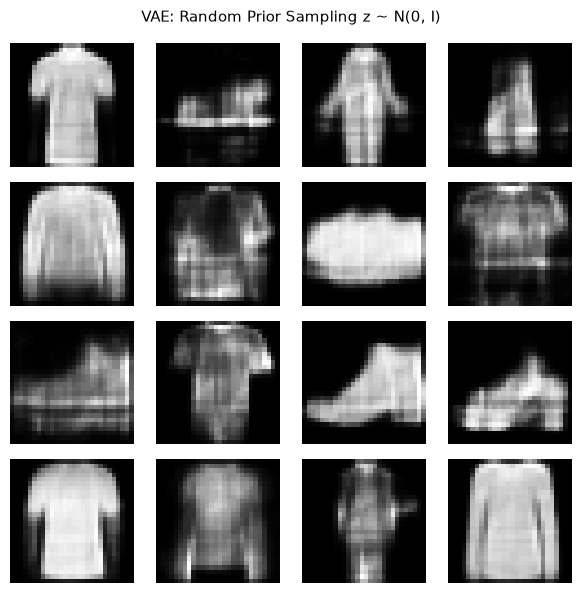

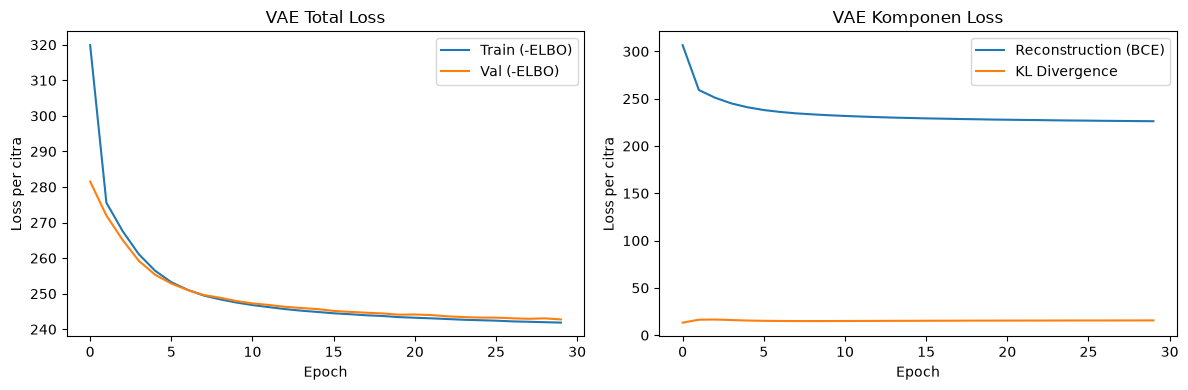

In [ ]:
# Figur 2 Panel A: Random Generative Sampling VAE dari prior z ~ N(0, I)
num_gen_samples = 16
torch.manual_seed(SEED)
vae.eval()
with torch.no_grad():
    z_prior = torch.randn(num_gen_samples, LATENT_DIM, device=device)
    x_vae_samples = vae.decoder(z_prior).cpu().numpy()

plt.figure(figsize=(6, 6))
for i in range(num_gen_samples):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_vae_samples[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.suptitle("VAE: Random Prior Sampling z ~ N(0, I)", fontsize=11, y=0.98)
plt.tight_layout()
plt.show()

# Kurva loss VAE (untuk Figur 5)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_vae["loss"], label="Train (-ELBO)")
plt.plot(history_vae["val_loss"], label="Val (-ELBO)")
plt.xlabel("Epoch"); plt.ylabel("Loss per citra"); plt.title("VAE Total Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_vae["recon_loss"], label="Reconstruction (BCE)")
plt.plot(history_vae["kl_loss"], label="KL Divergence")
plt.xlabel("Epoch"); plt.ylabel("Loss per citra"); plt.title("VAE Komponen Loss"); plt.legend()
plt.tight_layout()
plt.show()

## Vanilla GAN (MLP)

Vanilla GAN memakai lapisan fully-connected saja, tanpa konvolusi dan BatchNorm, sebagai pembanding DCGAN. Generator $G$ memetakan noise $z \sim \mathcal{N}(0, I)$ ke citra, sedangkan Discriminator $D$ memperkirakan probabilitas citra berasal dari data asli.

| Jaringan | Arsitektur | Aktivasi |
|---|---|---|
| Generator | 100 → 256 → 512 → 784 | LeakyReLU(0.2), LeakyReLU(0.2), Tanh |
| Discriminator | 784 → 512 → 256 → 1 | LeakyReLU(0.2), LeakyReLU(0.2), Sigmoid |

Objektif minimax:

$$\min_G \max_D \; \mathbb{E}_{x \sim P_{data}}[\log D(x)] + \mathbb{E}_{z \sim \mathcal{N}(0, I)}[\log(1 - D(G(z)))]$$

- Discriminator dilatih dengan BCE: $\mathcal{L}_D = -\log D(x) - \log(1 - D(G(z)))$.
- Generator memakai non-saturating loss $\mathcal{L}_G = -\log D(G(z))$ agar gradien tidak hilang di awal pelatihan.
- Citra diskalakan dari $[0, 1]$ ke $[-1, 1]$ agar sesuai dengan output Tanh.
- Optimizer: Adam, learning rate $2 \times 10^{-4}$, $\beta_1 = 0.5$, 30 epoch.

In [ ]:
nz_gan = 100  

class GeneratorMLP(nn.Module):
    """G: z (100) -> 256 -> 512 -> 784, output Tanh pada rentang [-1, 1]."""
    def __init__(self, nz=nz_gan):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(nz, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.main(z)

class DiscriminatorMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)

torch.manual_seed(SEED)
netG_mlp = GeneratorMLP().to(device)
netD_mlp = DiscriminatorMLP().to(device)
print(netG_mlp)
print(netD_mlp)

criterion_gan = nn.BCELoss()
optimizerG_mlp = torch.optim.Adam(netG_mlp.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizerD_mlp = torch.optim.Adam(netD_mlp.parameters(), lr=2e-4, betas=(0.5, 0.999))
fixed_noise_mlp = torch.randn(64, nz_gan, device=device)

GeneratorMLP(
  (main): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
  )
)
DiscriminatorMLP(
  (main): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=256, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
G_losses_mlp, D_losses_mlp = [], []                     # per iterasi
history_gan = {"G_loss": [], "D_loss": [], "epoch_time": []}  # per epoch (untuk Figur 5)

print("--- Mulai Pelatihan Vanilla GAN (MLP) ---")
for epoch in range(EPOCHS):
    netG_mlp.train(); netD_mlp.train()
    sync_device()
    t0 = time.perf_counter()
    sum_G, sum_D, n_iter = 0.0, 0.0, 0
    for xb, _ in train_loader:
        real = xb.to(device) * 2.0 - 1.0     
        b = real.size(0)
        ones  = torch.ones(b, 1, device=device)
        zeros = torch.zeros(b, 1, device=device)

        # (1) Update D: maximize log D(x) + log(1 - D(G(z)))
        optimizerD_mlp.zero_grad()
        z = torch.randn(b, nz_gan, device=device)
        fake = netG_mlp(z)
        errD = criterion_gan(netD_mlp(real), ones) + criterion_gan(netD_mlp(fake.detach()), zeros)
        errD.backward()
        optimizerD_mlp.step()

        # (2) Update G: non-saturating loss, maximize log D(G(z))
        optimizerG_mlp.zero_grad()
        errG = criterion_gan(netD_mlp(fake), ones)
        errG.backward()
        optimizerG_mlp.step()

        G_losses_mlp.append(errG.item()); D_losses_mlp.append(errD.item())
        sum_G += errG.item(); sum_D += errD.item(); n_iter += 1
    sync_device()
    epoch_time = time.perf_counter() - t0

    history_gan["G_loss"].append(sum_G / n_iter)
    history_gan["D_loss"].append(sum_D / n_iter)
    history_gan["epoch_time"].append(epoch_time)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - Loss_D: {sum_D / n_iter:.4f} - Loss_G: {sum_G / n_iter:.4f} - {epoch_time:.1f}s")

print(f"\nRata-rata training time per epoch: {np.mean(history_gan['epoch_time']):.2f} s")


--- Mulai Pelatihan Vanilla GAN (MLP) ---
Epoch 01/30 - Loss_D: 0.5770 - Loss_G: 1.3608 - 3.3s
Epoch 02/30 - Loss_D: 0.5654 - Loss_G: 2.8281 - 2.3s
Epoch 03/30 - Loss_D: 0.6684 - Loss_G: 2.8310 - 2.4s
Epoch 04/30 - Loss_D: 0.6888 - Loss_G: 2.7003 - 2.4s
Epoch 05/30 - Loss_D: 0.7259 - Loss_G: 2.5343 - 2.3s
Epoch 06/30 - Loss_D: 0.8113 - Loss_G: 2.2552 - 2.4s
Epoch 07/30 - Loss_D: 0.7367 - Loss_G: 2.3628 - 2.2s
Epoch 08/30 - Loss_D: 0.7081 - Loss_G: 2.3992 - 2.4s
Epoch 09/30 - Loss_D: 0.6981 - Loss_G: 2.4141 - 2.3s
Epoch 10/30 - Loss_D: 0.7789 - Loss_G: 2.3422 - 2.3s
Epoch 11/30 - Loss_D: 0.8292 - Loss_G: 2.0916 - 2.3s
Epoch 12/30 - Loss_D: 0.7754 - Loss_G: 2.0393 - 2.4s
Epoch 13/30 - Loss_D: 0.8252 - Loss_G: 2.0753 - 2.4s
Epoch 14/30 - Loss_D: 0.8445 - Loss_G: 1.9369 - 2.4s
Epoch 15/30 - Loss_D: 0.8171 - Loss_G: 2.0006 - 2.7s
Epoch 16/30 - Loss_D: 0.8784 - Loss_G: 1.9793 - 2.4s
Epoch 17/30 - Loss_D: 0.8631 - Loss_G: 1.8773 - 2.4s
Epoch 18/30 - Loss_D: 0.8816 - Loss_G: 1.8580 - 2.4s
Epoc

Vanilla GAN latency (batch 64): 0.908 ms


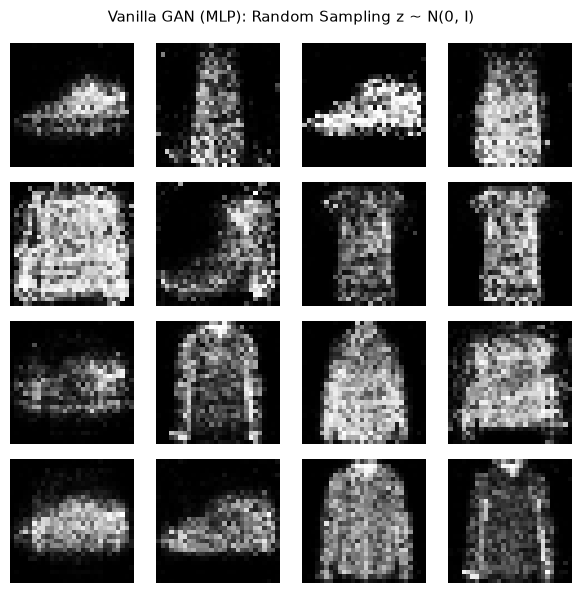

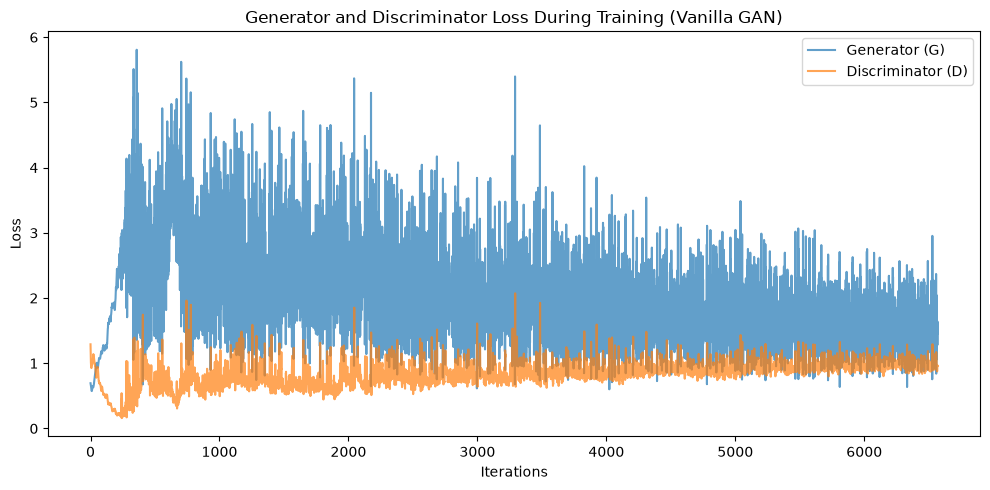

In [238]:
netG_mlp.eval()
latency_gan = measure_latency(lambda: netG_mlp(torch.randn(64, nz_gan, device=device)))
print(f"Vanilla GAN latency (batch 64): {latency_gan:.3f} ms")

# Figur 2 Panel B: sampel dari z ~ N(0, I)
with torch.no_grad():
    x_gan_samples = (netG_mlp(fixed_noise_mlp[:16]).cpu().numpy() + 1.0) / 2.0  # [-1,1] -> [0,1]

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_gan_samples[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.suptitle("Vanilla GAN (MLP): Random Sampling z ~ N(0, I)", fontsize=11, y=0.98)
plt.tight_layout()
plt.show()

# Kurva loss G dan D (Figur 5)
plt.figure(figsize=(10, 5))
plt.plot(G_losses_mlp, label="Generator (G)", alpha=0.7)
plt.plot(D_losses_mlp, label="Discriminator (D)", alpha=0.7)
plt.xlabel("Iterations"); plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss During Training (Vanilla GAN)")
plt.legend(); plt.tight_layout(); plt.show()


## Deep Convolutional GAN (DCGAN)

DCGAN memakai objektif dan loss yang sama dengan Vanilla GAN, tetapi Generator dan Discriminator dibangun dari lapisan konvolusi. Prinsip arsitektur DCGAN (strided convolution, BatchNorm, ReLU/LeakyReLU, tanpa lapisan fully-connected) membuat pelatihan lebih stabil.

| Jaringan | Alur dimensi | Lapisan |
|---|---|---|
| Generator | $z$ (100×1×1) → 256×4×4 → 128×7×7 → 64×14×14 → 1×28×28 | ConvTranspose2d + BatchNorm + ReLU, output Tanh |
| Discriminator | 1×28×28 → 64×14×14 → 128×7×7 → 256×4×4 → 1 | Conv2d + BatchNorm + LeakyReLU(0.2), output Sigmoid |

- Inisialisasi bobot: Conv $\sim \mathcal{N}(0, 0.02)$, BatchNorm weight $\sim \mathcal{N}(1, 0.02)$, bias 0.
- Loss: BCE, dengan non-saturating loss untuk Generator.
- Citra diskalakan ke $[-1, 1]$.
- Optimizer: Adam, learning rate $2 \times 10^{-4}$, $\beta_1 = 0.5$, 30 epoch.

In [239]:
import torchvision.utils as vutils

# Hyperparameter DCGAN
nz = 100       # Dimensi vektor laten z (input generator)
ngf = 64      # Ukuran fitur generator
ndf = 64      # Ukuran fitur discriminator
nc = 1        # Kanal citra (1 untuk grayscale Fashion-MNIST)
lr = 0.0002   # Learning rate standar DCGAN
beta1 = 0.5   # Hyperparameter beta1 Adam standar DCGAN
ngpu = 0

def weights_init(m):
    """Inisialisasi bobot standar DCGAN: normal(0, 0.02) untuk Conv dan BatchNorm"""
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

# ==============================================================================
# Generator DCGAN untuk 28x28 (nz -> 4x4 -> 7x7 -> 14x14 -> 28x28)
# ==============================================================================
class Generator(nn.Module):
    def __init__(self, ngpu):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # Input: (nz) x 1 x 1 -> State: (ngf*4) x 4 x 4
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # State: (ngf*4) x 4 x 4 -> State: (ngf*2) x 7 x 7
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 3, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # State: (ngf*2) x 7 x 7 -> State: (ngf) x 14 x 14
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # State: (ngf) x 14 x 14 -> Output: (nc) x 28 x 28
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        return self.main(input)

# ==============================================================================
# Discriminator DCGAN untuk 28x28 (28x28 -> 14x14 -> 7x7 -> 4x4 -> 1)
# ==============================================================================
class Discriminator(nn.Module):
    def __init__(self, ngpu):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # Input: (nc) x 28 x 28 -> State: (ndf) x 14 x 14
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (ndf) x 14 x 14 -> State: (ndf*2) x 7 x 7
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (ndf*2) x 7 x 7 -> State: (ndf*4) x 4 x 4
            nn.Conv2d(ndf * 2, ndf * 4, 3, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (ndf*4) x 4 x 4 -> Output: 1 x 1 x 1
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input)

In [240]:
torch.manual_seed(SEED)
# Create the generator
netG = Generator(ngpu).to(device)
# Handle multi-GPU if desired
if (device.type == 'cuda') and (ngpu > 1):
    netG = nn.DataParallel(netG, list(range(ngpu)))

# Apply the ``weights_init`` function to randomly initialize all weights
#  to ``mean=0``, ``stdev=0.02``.
netG.apply(weights_init)

# Print the model
print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): Tanh()
  )
)


In [241]:
# Create the Discriminator
netD = Discriminator(ngpu).to(device)


if (device.type == 'cuda') and (ngpu > 1):
    netD = nn.DataParallel(netD, list(range(ngpu)))

# Apply the ``weights_init`` function to randomly initialize all weights
# like this: ``to mean=0, stdev=0.2``.
netD.apply(weights_init)

# Print the model
print(netD)

Discriminator(
  (main): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (9): Sigmoid()
  )
)


In [242]:
import torch.optim as optim
import torchvision.utils as vutils

# Initialize the ``BCELoss`` function
criterion_gan = nn.BCELoss() 


fixed_noise = torch.randn(64, nz, 1, 1, device=device)

real_label = 1.
fake_label = 0.

optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

In [243]:
import time as _time

history_dcgan = {"G_loss": [], "D_loss": [], "epoch_time": []}

G_losses = []
D_losses = []
img_list = []

iters = 0
print("Starting Training Loop...")
for epoch in range(EPOCHS):
    netG.train(); netD.train()
    sync_device()
    t0 = _time.perf_counter()
    sum_G, sum_D, n_iter = 0.0, 0.0, 0

    for i, data in enumerate(train_loader):

        ############################
        # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
        ###########################
        ## Train with all-real batch
        netD.zero_grad()
        # Format batch
        real_cpu = data[0].view(-1, 1, 28, 28).to(device)
        real_cpu = real_cpu * 2.0 - 1.0
        b_size = real_cpu.size(0)

        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
        # Forward pass real batch through D
        output = netD(real_cpu).view(-1)
        # Calculate loss on all-real batch
        errD_real = criterion_gan(output, label)
        # Calculate gradients for D in backward pass
        errD_real.backward()
        D_x = output.mean().item()

        ## Train with all-fake batch
        # Generate batch of latent vectors
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        # Generate fake image batch with G
        fake = netG(noise)
        label.fill_(fake_label)
        # Classify all fake batch with D
        output = netD(fake.detach()).view(-1)
        # Calculate D's loss on the all-fake batch
        errD_fake = criterion_gan(output, label)
        # Calculate the gradients for this batch, accumulated (summed) with previous gradients
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # Compute error of D as sum over the fake and the real batches
        errD = errD_real + errD_fake
        # Update D
        optimizerD.step()

        ############################
        # (2) Update G network: maximize log(D(G(z)))
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # fake labels are real for generator cost
        # Since we just updated D, perform another forward pass of all-fake batch through D
        output = netD(fake).view(-1)
        # Calculate G's loss based on this output
        errG = criterion_gan(output, label)
        # Calculate gradients for G
        errG.backward()
        D_G_z2 = output.mean().item()
        # Update G
        optimizerG.step()

        # Output training stats
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch, EPOCHS, i, len(train_loader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

        # Save Losses for plotting later
        G_losses.append(errG.item())
        D_losses.append(errD.item())
        sum_G += errG.item(); sum_D += errD.item(); n_iter += 1

        # Check how the generator is doing by saving G's output on fixed_noise
        if (iters % 500 == 0) or ((epoch == EPOCHS-1) and (i == len(train_loader)-1)):
            with torch.no_grad():
                fake_vis = netG(fixed_noise).detach().cpu()
            img_list.append(vutils.make_grid(fake_vis, padding=2, normalize=True))

        iters += 1

    sync_device()
    epoch_time = _time.perf_counter() - t0
    history_dcgan["G_loss"].append(sum_G / n_iter)
    history_dcgan["D_loss"].append(sum_D / n_iter)
    history_dcgan["epoch_time"].append(epoch_time)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} ← Loss_D: {sum_D/n_iter:.4f} Loss_G: {sum_G/n_iter:.4f} - {epoch_time:.1f}s")

print(f"\nRata-rata training time per epoch: {np.mean(history_dcgan['epoch_time']):.2f} s")


Starting Training Loop...
[0/30][0/219]	Loss_D: 1.5324	Loss_G: 1.6950	D(x): 0.4069	D(G(z)): 0.3943 / 0.2107
[0/30][50/219]	Loss_D: 0.7879	Loss_G: 10.2045	D(x): 0.9718	D(G(z)): 0.4896 / 0.0001
[0/30][100/219]	Loss_D: 0.3686	Loss_G: 2.7383	D(x): 0.8065	D(G(z)): 0.1111 / 0.0800
[0/30][150/219]	Loss_D: 0.1826	Loss_G: 2.8430	D(x): 0.9099	D(G(z)): 0.0749 / 0.0760
[0/30][200/219]	Loss_D: 0.1690	Loss_G: 3.4040	D(x): 0.8995	D(G(z)): 0.0532 / 0.0450
Epoch 01/30 ← Loss_D: 0.3648 Loss_G: 3.5242 - 55.6s
[1/30][0/219]	Loss_D: 0.1570	Loss_G: 3.5258	D(x): 0.9225	D(G(z)): 0.0596 / 0.0414
[1/30][50/219]	Loss_D: 0.1274	Loss_G: 3.3907	D(x): 0.9400	D(G(z)): 0.0585 / 0.0470
[1/30][100/219]	Loss_D: 0.1728	Loss_G: 3.1083	D(x): 0.9255	D(G(z)): 0.0814 / 0.0647
[1/30][150/219]	Loss_D: 0.3634	Loss_G: 2.4881	D(x): 0.8407	D(G(z)): 0.1508 / 0.1137
[1/30][200/219]	Loss_D: 0.2456	Loss_G: 4.5316	D(x): 0.9528	D(G(z)): 0.1652 / 0.0171
Epoch 02/30 ← Loss_D: 0.3458 Loss_G: 3.2419 - 36.9s
[2/30][0/219]	Loss_D: 0.3453	Loss_G

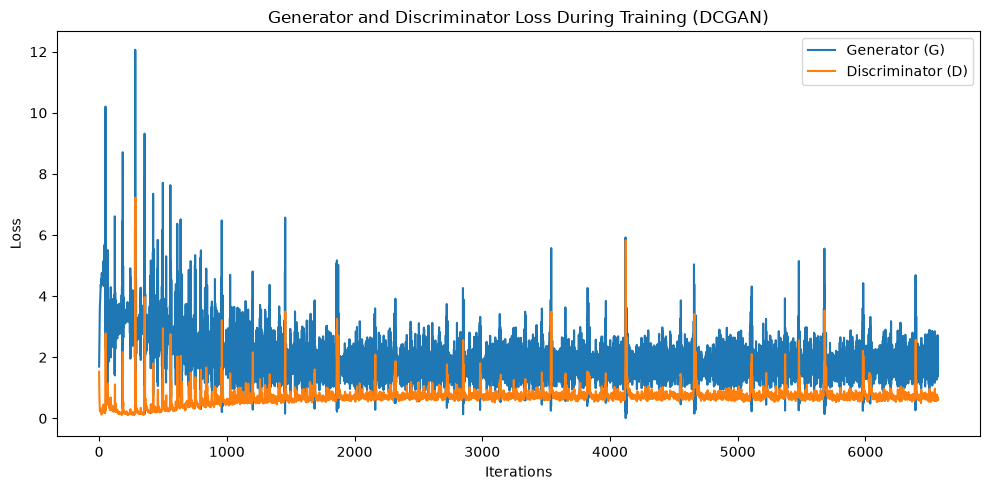

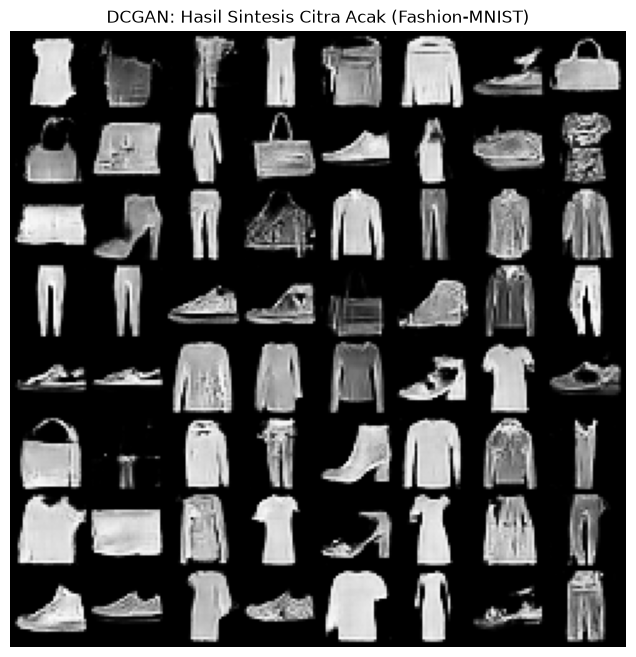

DCGAN latency (batch 64): 6.415 ms
DCGAN training time / epoch: 41.33 s


In [244]:
# ==============================================================================
# VISUALISASI HASIL DCGAN
# ==============================================================================

# 1. Plot Kurva Training Loss (Figur 5 Laporan)
plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training (DCGAN)")
plt.plot(G_losses, label="Generator (G)")
plt.plot(D_losses, label="Discriminator (D)")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Visualisasi Sampel Citra Sintetis dari Generator (Figur 2 Panel C Laporan)
# Ambil hasil generate terakhir dari fixed_noise
with torch.no_grad():
    fake_samples = netG(fixed_noise).detach().cpu()

# Skala kembali dari [-1, 1] ke [0, 1] untuk plotting
fake_samples = (fake_samples + 1.0) / 2.0

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("DCGAN: Hasil Sintesis Citra Acak (Fashion-MNIST)")
# Buat grid 8x8 (64 citra)
grid_img = vutils.make_grid(fake_samples[:64], padding=2, normalize=False)
plt.imshow(np.transpose(grid_img.numpy(), (1, 2, 0)))
plt.show()
# Latency DCGAN (batch 64)
netG.eval()
latency_dcgan = measure_latency(lambda: netG(torch.randn(64, nz, 1, 1, device=device)), n_runs=20)
print(f"DCGAN latency (batch 64): {latency_dcgan:.3f} ms")
print(f"DCGAN training time / epoch: {np.mean(history_dcgan['epoch_time']):.2f} s")


## Denoising Diffusion Probabilistic Model (DDPM)

DDPM membangkitkan citra dengan membalik proses penambahan derau secara bertahap. *Forward process* menambahkan derau Gaussian ke citra selama $T = 1000$ langkah sampai citra menjadi derau murni. Sebuah U-Net $\epsilon_\theta(x_t, t)$ dilatih untuk memprediksi derau tersebut, lalu dipakai pada *reverse process* untuk mengubah $x_T \sim \mathcal{N}(0, I)$ kembali menjadi citra.

**Forward process** (dapat dihitung langsung untuk sembarang $t$):

$$q(x_t \mid x_0) = \mathcal{N}\left(\sqrt{\bar\alpha_t}\, x_0,\; (1 - \bar\alpha_t) I\right), \quad \bar\alpha_t = \prod_{s=1}^{t} (1 - \beta_s)$$

**Loss** (simplified objective, Ho et al. 2020):

$$\mathcal{L}_{simple} = \mathbb{E}_{x_0, t, \epsilon}\left[\lVert \epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}\, x_0 + \sqrt{1 - \bar\alpha_t}\, \epsilon,\; t) \rVert^2\right]$$

**Reverse process** (satu langkah sampling):

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\, \epsilon_\theta(x_t, t)\right) + \sigma_t z, \quad \sigma_t^2 = \beta_t, \; z \sim \mathcal{N}(0, I)$$

| Komponen | Konfigurasi |
|---|---|
| Noise schedule | linear, $\beta_1 = 10^{-4}$ sampai $\beta_T = 0.02$, $T = 1000$ |
| Network | U-Net 28 → 14 → 7 → 14 → 28, ResBlock (GroupNorm + SiLU), skip connection, sinusoidal time embedding |
| Kanal | 32 → 64 → 128 |
| Input | citra diskalakan ke $[-1, 1]$ |
| Optimizer | Adam, learning rate $2 \times 10^{-4}$, 30 epoch |


In [245]:
import math

T_STEPS = 1000  # Jumlah langkah diffusion T

class SinusoidalTimeEmbedding(nn.Module):
    """Embedding posisi sinusoidal untuk timestep t (seperti positional encoding Transformer)."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=1)

class ResBlock(nn.Module):
    """Residual block: GroupNorm -> SiLU -> Conv, dengan injeksi time embedding."""
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class UNet(nn.Module):
    """U-Net kecil untuk 28x28: 28 -> 14 -> 7 -> 14 -> 28, memprediksi derau eps."""
    def __init__(self, ch=32, t_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(ch), nn.Linear(ch, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim)
        )
        self.conv_in = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)                      # ch x 28 x 28
        self.pool1 = nn.Conv2d(ch, ch, 4, 2, 1)                   # -> 14 x 14
        self.down2 = ResBlock(ch, ch * 2, t_dim)                  # 2ch x 14 x 14
        self.pool2 = nn.Conv2d(ch * 2, ch * 2, 4, 2, 1)           # -> 7 x 7
        self.mid1 = ResBlock(ch * 2, ch * 4, t_dim)               # 4ch x 7 x 7
        self.mid2 = ResBlock(ch * 4, ch * 2, t_dim)               # 2ch x 7 x 7
        self.up2 = nn.ConvTranspose2d(ch * 2, ch * 2, 4, 2, 1)    # -> 14 x 14
        self.dec2 = ResBlock(ch * 4, ch * 2, t_dim)               # concat skip dari down2
        self.up1 = nn.ConvTranspose2d(ch * 2, ch, 4, 2, 1)        # -> 28 x 28
        self.dec1 = ResBlock(ch * 2, ch, t_dim)                   # concat skip dari down1
        self.conv_out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        h1 = self.down1(self.conv_in(x), t_emb)
        h2 = self.down2(self.pool1(h1), t_emb)
        m = self.mid2(self.mid1(self.pool2(h2), t_emb), t_emb)
        u2 = self.dec2(torch.cat([self.up2(m), h2], dim=1), t_emb)
        u1 = self.dec1(torch.cat([self.up1(u2), h1], dim=1), t_emb)
        return self.conv_out(u1)

# Linear noise schedule (Ho et al., 2020): beta_1 = 1e-4 sampai beta_T = 0.02
betas = torch.linspace(1e-4, 0.02, T_STEPS, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, eps):
    """Forward process: x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps."""
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

torch.manual_seed(SEED)
ddpm = UNet().to(device)
optimizer_ddpm = torch.optim.Adam(ddpm.parameters(), lr=2e-4)
print(f"Jumlah parameter U-Net: {sum(p.numel() for p in ddpm.parameters()):,}")


Jumlah parameter U-Net: 826,561


In [255]:
history_ddpm = {"loss": [], "val_loss": [], "epoch_time": []}

@torch.no_grad()
def eval_ddpm(loader):
    # Generator tetap agar t dan eps pada validasi sama di setiap epoch
    ddpm.eval()
    g = torch.Generator(device="cpu").manual_seed(SEED)
    total, n = 0.0, 0
    for xb, _ in loader:
        x0 = (xb.view(-1, 1, 28, 28) * 2.0 - 1.0).to(device)
        t = torch.randint(0, T_STEPS, (x0.size(0),), generator=g).to(device)
        eps = torch.randn(x0.shape, generator=g).to(device)
        total += F.mse_loss(ddpm(q_sample(x0, t, eps), t), eps).item() * x0.size(0)
        n += x0.size(0)
    return total / n

print("--- Mulai Pelatihan DDPM ---")
for epoch in range(EPOCHS):
    ddpm.train()
    sync_device()
    t0 = time.perf_counter()
    total, n = 0.0, 0
    for xb, _ in train_loader:
        x0 = (xb.view(-1, 1, 28, 28) * 2.0 - 1.0).to(device)    # [0, 1] -> [-1, 1]
        t = torch.randint(0, T_STEPS, (x0.size(0),), device=device)  # t ~ Uniform{1..T}
        eps = torch.randn_like(x0)
        loss = F.mse_loss(ddpm(q_sample(x0, t, eps), t), eps)   # || eps - eps_theta(x_t, t) ||^2
        optimizer_ddpm.zero_grad()
        loss.backward()
        optimizer_ddpm.step()
        total += loss.item() * x0.size(0)
        n += x0.size(0)
    sync_device()
    epoch_time = time.perf_counter() - t0
    val_loss = eval_ddpm(val_loader)

    history_ddpm["loss"].append(total / n)
    history_ddpm["val_loss"].append(val_loss)
    history_ddpm["epoch_time"].append(epoch_time)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - loss: {total / n:.4f} - val_loss: {val_loss:.4f} - {epoch_time:.1f}s")

print(f"\nRata-rata training time per epoch: {np.mean(history_ddpm['epoch_time']):.2f} s")


--- Mulai Pelatihan DDPM ---
Epoch 01/30 - loss: 0.0565 - val_loss: 0.0549 - 59.7s
Epoch 02/30 - loss: 0.0535 - val_loss: 0.0518 - 51.3s
Epoch 03/30 - loss: 0.0508 - val_loss: 0.0502 - 79.9s
Epoch 04/30 - loss: 0.0503 - val_loss: 0.0484 - 107.5s
Epoch 05/30 - loss: 0.0475 - val_loss: 0.0472 - 88.0s
Epoch 06/30 - loss: 0.0465 - val_loss: 0.0466 - 76.5s
Epoch 07/30 - loss: 0.0455 - val_loss: 0.0460 - 74.6s
Epoch 08/30 - loss: 0.0455 - val_loss: 0.0453 - 83.9s
Epoch 09/30 - loss: 0.0452 - val_loss: 0.0447 - 81.5s
Epoch 10/30 - loss: 0.0441 - val_loss: 0.0441 - 100.0s
Epoch 11/30 - loss: 0.0434 - val_loss: 0.0436 - 72.7s
Epoch 12/30 - loss: 0.0438 - val_loss: 0.0436 - 75.6s
Epoch 13/30 - loss: 0.0425 - val_loss: 0.0429 - 88.8s
Epoch 14/30 - loss: 0.0432 - val_loss: 0.0428 - 94.7s
Epoch 15/30 - loss: 0.0428 - val_loss: 0.0426 - 92.0s
Epoch 16/30 - loss: 0.0418 - val_loss: 0.0422 - 92.0s
Epoch 17/30 - loss: 0.0419 - val_loss: 0.0422 - 97.0s
Epoch 18/30 - loss: 0.0421 - val_loss: 0.0417 - 93.

DDPM latency (batch 64, 1000 langkah): 17126.0 ms


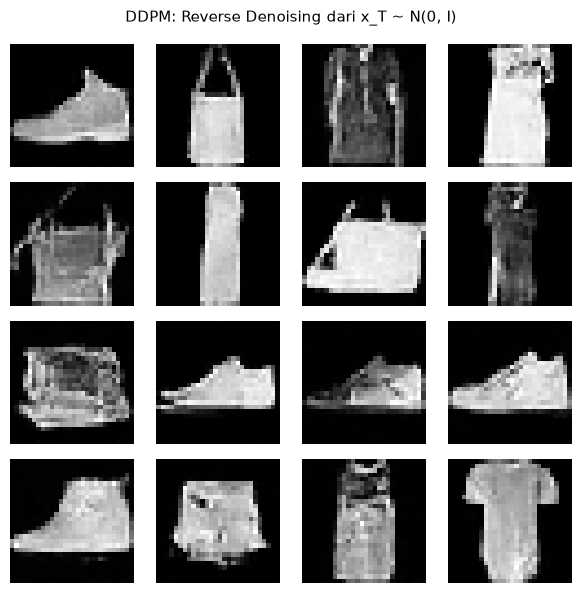

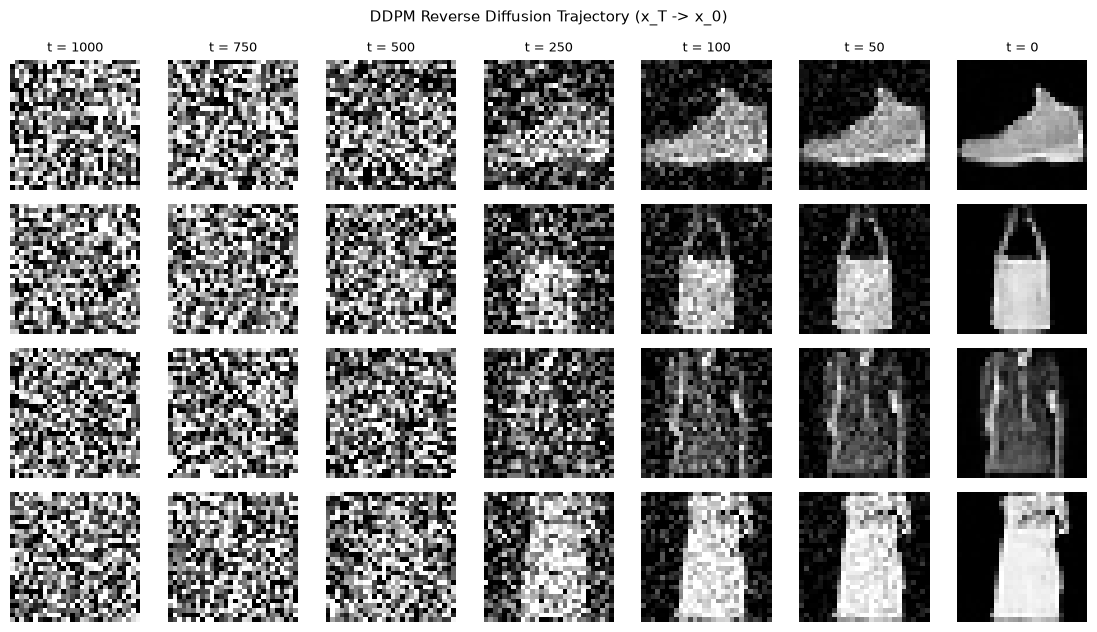

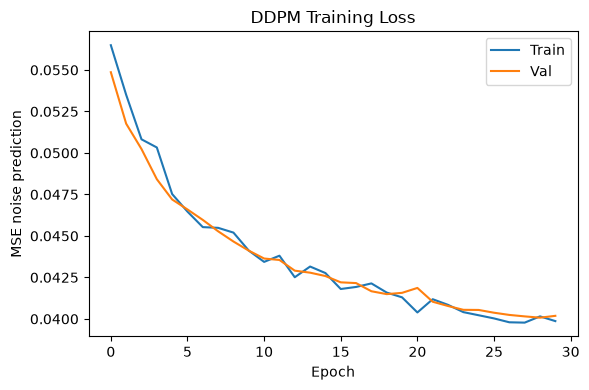

In [259]:
# Pastikan schedule tensor diffusion terdefinisi dengan benar (tidak tertimpa variabel lain)
betas = torch.linspace(1e-4, 0.02, T_STEPS, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

@torch.no_grad()
def ddpm_sample(n, save_steps=()):
    """Reverse process (Algoritma 2 Ho et al.): x_T ~ N(0, I) -> x_0 dalam T langkah."""
    ddpm.eval()
    x = torch.randn(n, 1, 28, 28, device=device)
    trajectory = {T_STEPS: x.cpu()}
    for t in reversed(range(T_STEPS)):
        t_batch = torch.full((n,), t, device=device, dtype=torch.long)
        eps_pred = ddpm(x, t_batch)
        mean = (x - betas[t] / (1 - alpha_bars[t]).sqrt() * eps_pred) / alphas[t].sqrt()
        if t > 0:
            x = mean + betas[t].sqrt() * torch.randn_like(x)   # sigma_t^2 = beta_t
        else:
            x = mean
        if t in save_steps:
            trajectory[t] = x.cpu()
    return x.clamp(-1, 1), trajectory

# Latency: 1 batch 64 sampel, 1000 langkah denoising (jauh lebih lambat dari GAN/VAE single-pass)
latency_ddpm = measure_latency(lambda: ddpm_sample(64), n_runs=3, n_warmup=1)
print(f"DDPM latency (batch 64, {T_STEPS} langkah): {latency_ddpm:.1f} ms")

# Figur 2 Panel D: 16 sampel dari x_T ~ N(0, I)
torch.manual_seed(SEED)
save_steps = [750, 500, 250, 100, 50, 0]
x_ddpm, traj = ddpm_sample(16, save_steps=save_steps)
x_ddpm_samples = ((x_ddpm + 1.0) / 2.0).cpu().numpy()   # [-1, 1] -> [0, 1]

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_ddpm_samples[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.suptitle("DDPM: Reverse Denoising dari x_T ~ N(0, I)", fontsize=11, y=0.98)
plt.tight_layout()
plt.show()

# Figur 5: Denoising trajectory x_T -> x_0 untuk 4 sampel
steps = [T_STEPS] + save_steps
n_show = 4
fig, axes = plt.subplots(n_show, len(steps), figsize=(1.6 * len(steps), 1.6 * n_show))
for r in range(n_show):
    for c, t in enumerate(steps):
        img = ((traj[t][r, 0].clamp(-1, 1) + 1.0) / 2.0).numpy()
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(f"t = {t}", fontsize=9)
plt.suptitle("DDPM Reverse Diffusion Trajectory (x_T -> x_0)", fontsize=11)
plt.tight_layout()
plt.show()

# Kurva loss prediksi derau (Figur 5)
plt.figure(figsize=(6, 4))
plt.plot(history_ddpm["loss"], label="Train")
plt.plot(history_ddpm["val_loss"], label="Val")
plt.xlabel("Epoch"); plt.ylabel("MSE noise prediction"); plt.title("DDPM Training Loss")
plt.legend(); plt.tight_layout(); plt.show()


## Figur 3: Visualisasi Gabungan Tahap 2–5 (MLP Classifier Experiments)

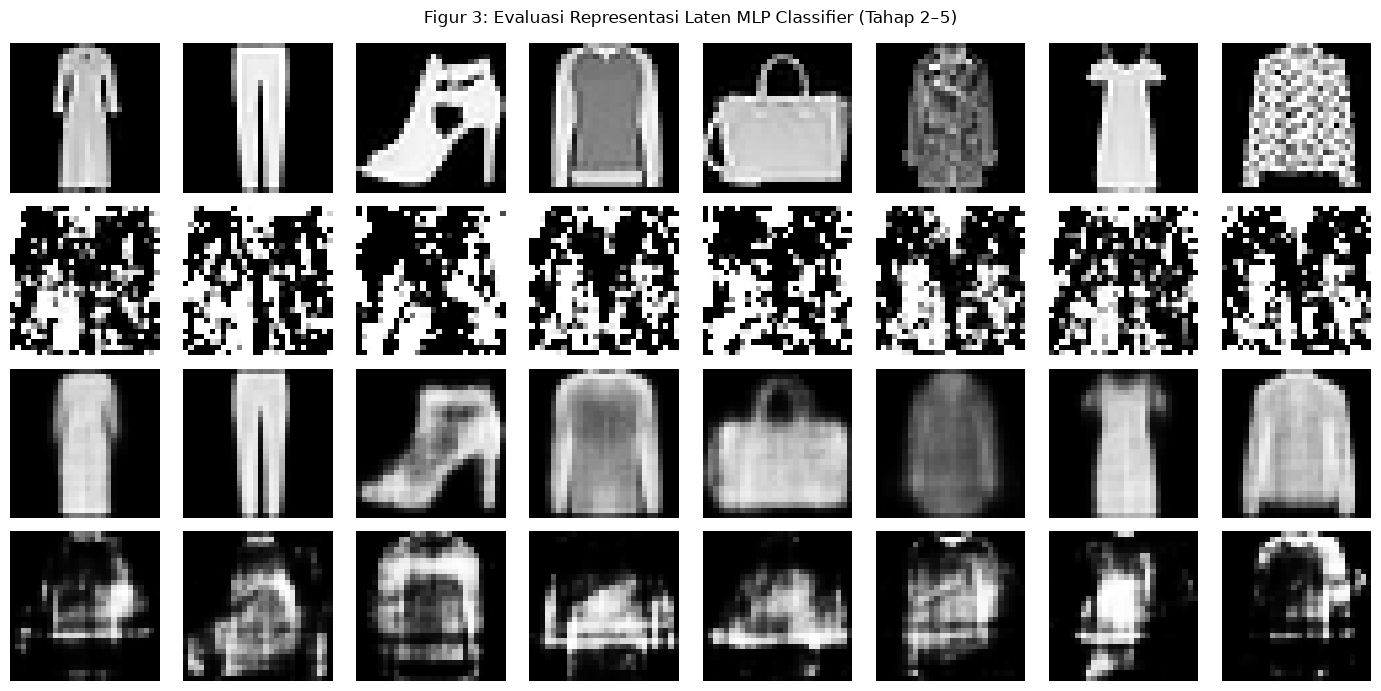

In [260]:
# =============================================================================
# Figur 3: Empat Panel — Ground Truth / Proyeksi W^T / Frozen vs Vanilla AE / Prior Sampling
# =============================================================================
n_show = 8
indices = list(range(n_show))

# Panel A: Ground Truth
panel_a = X_test[indices]

# Panel B: Proyeksi balik W^T dari z_MLP citra uji (Tahap 3)
try:
    panel_b = x_proj[:n_show]
except NameError:
    z_real_samples = z_test[:n_show]
    h1_proj = relu(z_real_samples @ W2.T)
    panel_b = sigmoid(h1_proj @ W1.T)

# Panel C: Rekonstruksi Frozen Latent Decoder (Tahap 4)
try:
    panel_c = X_test_pred_frozen[:n_show]
except NameError:
    panel_c = predict(frozen_autoencoder, X_test[:n_show])

# Panel D: Random Prior Sampling Ruang Laten MLP (Tahap 5)
try:
    panel_d = x_sampled[:n_show]
except NameError:
    mu_z = np.mean(z_test, axis=0)
    sigma_z = np.std(z_test, axis=0)
    z_rand = np.random.normal(loc=mu_z, scale=sigma_z, size=(n_show, 64))
    panel_d = predict(decoder, z_rand.astype(np.float32))

row_labels = [
    "Ground Truth\n(Citra Asli)",
    "Proyeksi W^T\n(Tahap 3)",
    "Frozen Latent\nDecoder (Tahap 4)",
    "Prior Sampling\nMLP (Tahap 5)",
]
panels = [panel_a, panel_b, panel_c, panel_d]

fig, axes = plt.subplots(4, n_show, figsize=(14, 7))
for r, (label, panel) in enumerate(zip(row_labels, panels)):
    for c in range(n_show):
        ax = axes[r, c]
        img = panel[c]
        ax.imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if c == 0:
            ax.set_ylabel(label, fontsize=8, rotation=0, labelpad=65, va="center")

fig.suptitle("Figur 3: Evaluasi Representasi Laten MLP Classifier (Tahap 2–5)", fontsize=12)
plt.tight_layout()
plt.show()


## Figur 4: Interpolasi Ruang Laten

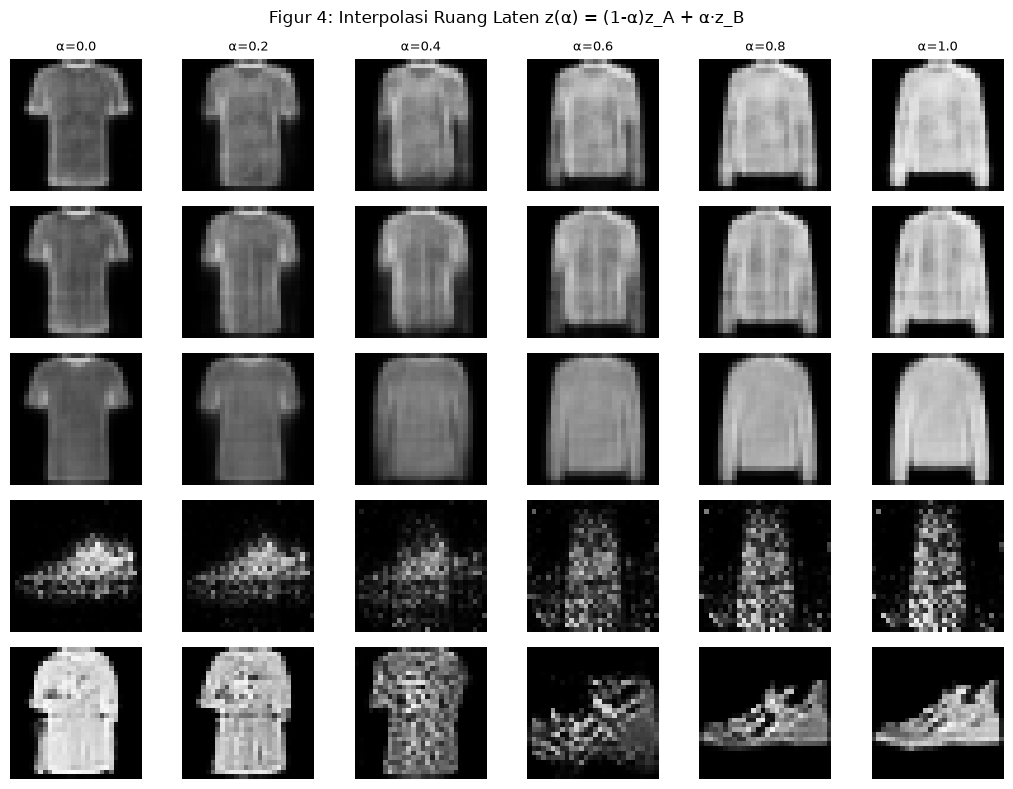

In [261]:
# =============================================================================
# Figur 4: Interpolasi Ruang Laten — Vanilla AE, Sparse AE, VAE, Vanilla GAN, DCGAN
# =============================================================================
interp_alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
n_alpha = len(interp_alphas)

def lerp(zA, zB, alpha_list):
    """Interpolasi linier: z(α) = (1-α)*zA + α*zB"""
    return [(1 - a) * zA + a * zB for a in alpha_list]

# Ambil 2 citra dari kelas berbeda (kelas 0 = T-shirt, kelas 6 = Shirt)
idx_A = np.where(y_test == 0)[0][0]
idx_B = np.where(y_test == 6)[0][0]
xA = torch.as_tensor(X_test[[idx_A]], dtype=torch.float32, device=device)
xB = torch.as_tensor(X_test[[idx_B]], dtype=torch.float32, device=device)

model_interp_results = {}

# --- (a) Vanilla AE ---
vanilla_ae.eval()
with torch.no_grad():
    zA_van = vanilla_ae_enc(xA).squeeze(0)
    zB_van = vanilla_ae_enc(xB).squeeze(0)
    interp_van = lerp(zA_van, zB_van, interp_alphas)
    imgs_van = [vanilla_ae_dec(z.unsqueeze(0)).squeeze(0).cpu().numpy() for z in interp_van]
model_interp_results["Vanilla AE"] = imgs_van

# --- (b) Sparse AE ---
sparse_ae.eval()
with torch.no_grad():
    zA_sp = sparse_ae.encoder(xA).squeeze(0)
    zB_sp = sparse_ae.encoder(xB).squeeze(0)
    interp_sp = lerp(zA_sp, zB_sp, interp_alphas)
    imgs_sp = [sparse_ae.decoder(z.unsqueeze(0)).squeeze(0).cpu().numpy() for z in interp_sp]
model_interp_results["Sparse AE"] = imgs_sp

# --- (c) VAE ---
vae.eval()
with torch.no_grad():
    muA, _ = vae.encode(xA)
    muB, _ = vae.encode(xB)
    zA_vae = muA.squeeze(0); zB_vae = muB.squeeze(0)
    interp_vae = lerp(zA_vae, zB_vae, interp_alphas)
    imgs_vae = [vae.decoder(z.unsqueeze(0)).squeeze(0).cpu().numpy() for z in interp_vae]
model_interp_results["VAE"] = imgs_vae

# --- (d) Vanilla GAN — tidak ada encoder, gunakan dua noise vector acak ---
torch.manual_seed(SEED)
netG_mlp.eval()
with torch.no_grad():
    nz_vgan = nz_gan if 'nz_gan' in globals() else 100
    zA_gan = torch.randn(nz_vgan, device=device)
    zB_gan = torch.randn(nz_vgan, device=device)
    interp_gan = lerp(zA_gan, zB_gan, interp_alphas)
    imgs_gan = [((netG_mlp(z.unsqueeze(0)).squeeze(0).cpu().numpy() + 1.0) / 2.0) for z in interp_gan]
model_interp_results["Vanilla GAN"] = imgs_gan

# --- (e) DCGAN — sama, dua noise vector acak ---
netG.eval()
with torch.no_grad():
    nz_dc = nz if 'nz' in globals() else 100
    zA_dcgan = torch.randn(nz_dc, 1, 1, device=device)
    zB_dcgan = torch.randn(nz_dc, 1, 1, device=device)
    interp_dcgan = lerp(zA_dcgan, zB_dcgan, interp_alphas)
    imgs_dcgan = [((netG(z.unsqueeze(0)).squeeze().cpu().numpy() + 1.0) / 2.0) for z in interp_dcgan]
model_interp_results["DCGAN"] = imgs_dcgan

# Plot Figur 4
n_models = len(model_interp_results)
fig, axes = plt.subplots(n_models, n_alpha, figsize=(n_alpha * 1.6 + 1, n_models * 1.6))
for r, (model_name, imgs) in enumerate(model_interp_results.items()):
    for c, (img, alpha) in enumerate(zip(imgs, interp_alphas)):
        ax = axes[r, c]
        if img.ndim == 1:
            img = img.reshape(28, 28)
        elif img.ndim == 2 and img.shape[0] in [1, 3]:
            img = img[0]
        ax.imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if r == 0:
            ax.set_title(f"α={alpha:.1f}", fontsize=9)
        if c == 0:
            ax.set_ylabel(model_name, fontsize=9, rotation=0, labelpad=55, va="center")

fig.suptitle("Figur 4: Interpolasi Ruang Laten z(α) = (1-α)z_A + α·z_B", fontsize=12)
plt.tight_layout()
plt.show()


## Figur 5: Kurva Training Loss Semua Model

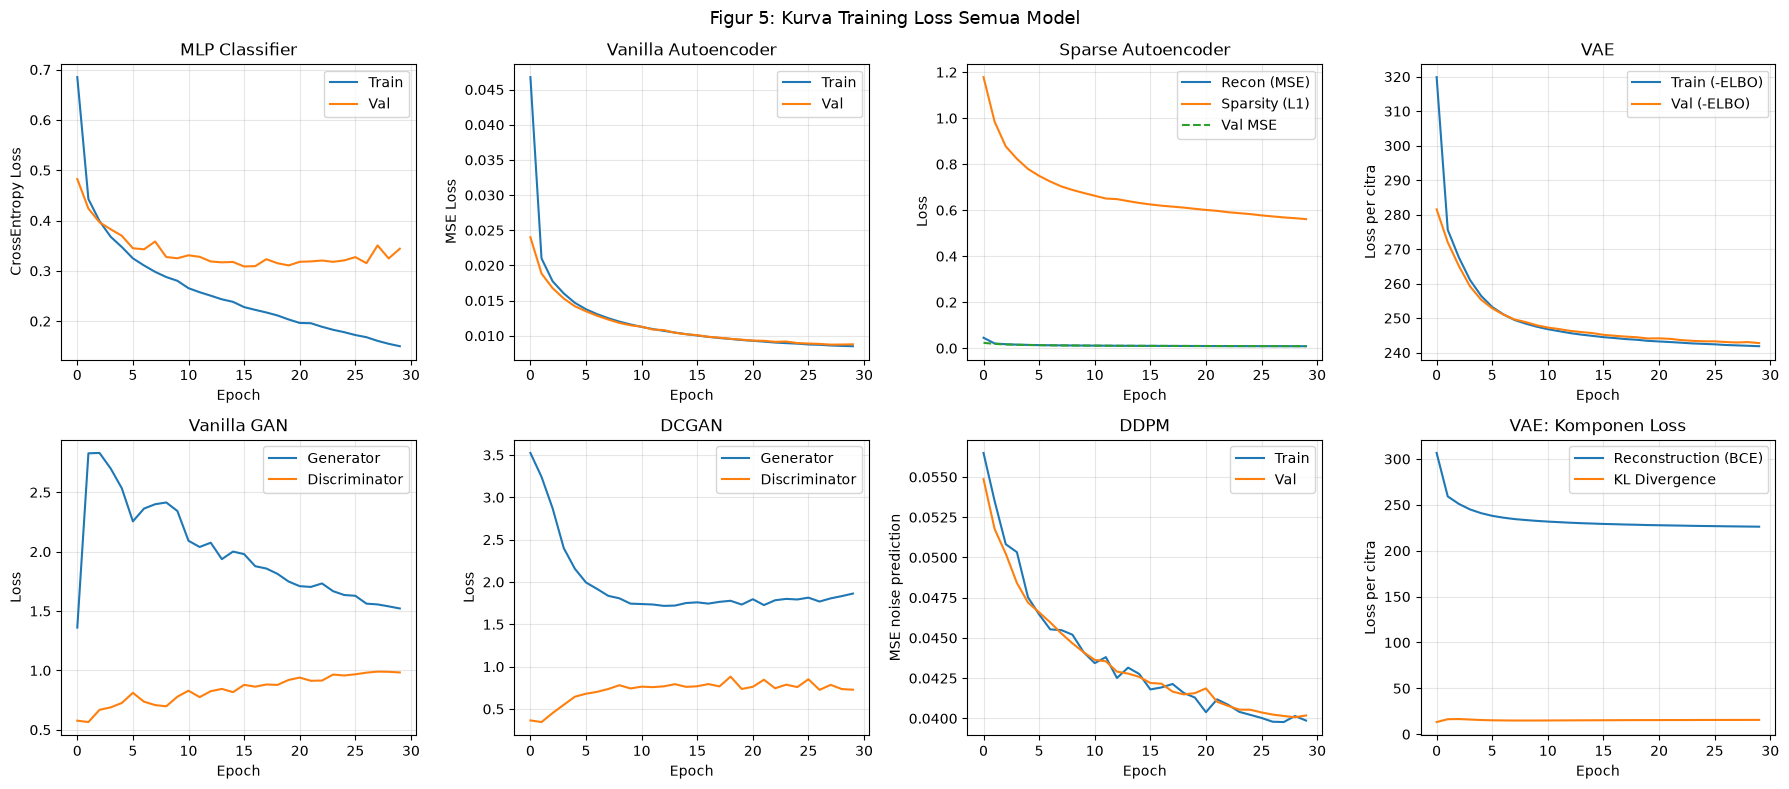

In [262]:
# =============================================================================
# Figur 5: Kurva Training Loss Semua Model
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Figur 5: Kurva Training Loss Semua Model", fontsize=13)

# --- (1) MLP Classifier ---
ax = axes[0, 0]
try:
    ax.plot(history_mlp["loss"], label="Train")
    ax.plot(history_mlp["val_loss"], label="Val")
except:
    pass
ax.set_title("MLP Classifier")
ax.set_xlabel("Epoch"); ax.set_ylabel("CrossEntropy Loss")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (2) Vanilla AE ---
ax = axes[0, 1]
ax.plot(history_vanilla["loss"], label="Train")
ax.plot(history_vanilla["val_loss"], label="Val")
ax.set_title("Vanilla Autoencoder")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (3) Sparse AE ---
ax = axes[0, 2]
ax.plot(history_sparse["recon_loss"], label="Recon (MSE)")
ax.plot(history_sparse["sparsity_loss"], label="Sparsity (L1)")
ax.plot(history_sparse["val_loss"], label="Val MSE", linestyle="--")
ax.set_title("Sparse Autoencoder")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (4) VAE ---
ax = axes[0, 3]
ax.plot(history_vae["loss"], label="Train (-ELBO)")
ax.plot(history_vae["val_loss"], label="Val (-ELBO)")
ax.set_title("VAE")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss per citra")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (5) Vanilla GAN ---
ax = axes[1, 0]
ax.plot(history_gan["G_loss"], label="Generator")
ax.plot(history_gan["D_loss"], label="Discriminator")
ax.set_title("Vanilla GAN")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (6) DCGAN ---
ax = axes[1, 1]
ax.plot(history_dcgan["G_loss"], label="Generator")
ax.plot(history_dcgan["D_loss"], label="Discriminator")
ax.set_title("DCGAN")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (7) DDPM ---
ax = axes[1, 2]
ax.plot(history_ddpm["loss"], label="Train")
ax.plot(history_ddpm["val_loss"], label="Val")
ax.set_title("DDPM")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE noise prediction")
ax.legend(); ax.grid(True, alpha=0.3)

# --- (8) VAE Component Losses ---
ax = axes[1, 3]
ax.plot(history_vae["recon_loss"], label="Reconstruction (BCE)")
ax.plot(history_vae["kl_loss"], label="KL Divergence")
ax.set_title("VAE: Komponen Loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss per citra")
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [263]:
import numpy as np
from scipy import linalg
import torch
import torch.nn.functional as F
from pytorch_fid.inception import InceptionV3

# ==============================================================================
# FUNGSI PERHITUNGAN FRÉCHET DISTANCE (FID)
# Rumus: d^2 = ||mu1 - mu2||^2 + Tr(Sigma1 + Sigma2 - 2 * (Sigma1 * Sigma2)^(1/2))
# ==============================================================================
def calculate_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    """
    Menghitung Fréchet Distance (Wasserstein-2 distance) antara dua distribusi Gaussian multivariat:
    X_1 ~ N(mu1, sigma1) dan X_2 ~ N(mu2, sigma2).
    
    Parameter:
    -- mu1, mu2       : Vektor rata-rata (mean) aktivasi Inception (dimensi 2048)
    -- sigma1, sigma2 : Matriks kovariansi aktivasi Inception (2048 x 2048)
    -- eps            : Faktor regularisasi numerik untuk mencegah singularitas
    
    Return:
    -- fid            : Nilai Fréchet Inception Distance (semakin kecil semakin baik)
    """
    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    assert mu1.shape == mu2.shape, f"Dimensi mean tidak cocok: {mu1.shape} vs {mu2.shape}"
    assert sigma1.shape == sigma2.shape, f"Dimensi kovariansi tidak cocok: {sigma1.shape} vs {sigma2.shape}"

    diff = mu1 - mu2

    # Perkalian matriks kovariansi: sigma1 @ sigma2
    # Catatan: sigma1 @ sigma2 mungkin non-simetris secara numerik, gunakan sqrtm
    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    if isinstance(covmean, tuple):
        covmean = covmean[0]

    # Penanganan jika matriks singular / hampir singular (NaN atau Inf)
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
        if isinstance(covmean, tuple):
            covmean = covmean[0]

    # Komponen imajiner numerik kecil (akibat floating point precision)
    if np.iscomplexobj(covmean):
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            m = np.max(np.abs(covmean.imag))
            raise ValueError(f"Komponen imajiner signifikan terdeteksi: {m}")
        covmean = covmean.real

    tr_covmean = np.trace(covmean)

    # Formula FID: ||mu1 - mu2||^2 + Tr(sigma1) + Tr(sigma2) - 2 * Tr(sqrt(sigma1 * sigma2))
    fid = diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2.0 * tr_covmean
    return float(np.real(fid))

# ==============================================================================
# 1. Inisialisasi Model InceptionV3 (Fitur 2048-dimensi)
# ==============================================================================
dims = 2048
block_idx = InceptionV3.BLOCK_INDEX_BY_DIM[dims]
inception_model = InceptionV3([block_idx], resize_input=True).to(device).eval()

def extract_inception_features(images_tensor, model, batch_size=64):
    """
    Ekstrak representasi fitur 2048-dimensi dari InceptionV3.
    images_tensor: Tensor float berukuran (N, 1, 28, 28) dengan rentang [0.0, 1.0]
    """
    n_samples = images_tensor.shape[0]
    features = []
    
    with torch.no_grad():
        for i in range(0, n_samples, batch_size):
            batch = images_tensor[i:i + batch_size].to(device)
            # Replikasi kanal 1 -> 3 kanal RGB agar kompatibel dengan InceptionV3
            if batch.shape[1] == 1:
                batch = batch.repeat(1, 3, 1, 1)
            
            feat = model(batch)[0]
            # Squeeze output spasial menjadi vektor (batch_size, 2048)
            if feat.size(2) != 1 or feat.size(3) != 1:
                feat = F.adaptive_avg_pool2d(feat, output_size=(1, 1))
            features.append(feat.squeeze(3).squeeze(2).cpu().numpy())
            
    features = np.concatenate(features, axis=0)
    mu = np.mean(features, axis=0)
    sigma = np.cov(features, rowvar=False)
    return mu, sigma

# ==============================================================================
# 2. Ekstrak Statistik Distribusi Citra Asli (Test Set)
# ==============================================================================
print("1. Mengekstrak fitur Inception untuk Real Test Set (7.000 citra)...")
x_real_test_tensor = torch.as_tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)
mu_real, sigma_real = extract_inception_features(x_real_test_tensor, inception_model, batch_size=128)
print("   Statistik citra asli selesai dihitung.")

# ==============================================================================
# 3. Fungsi Generator Sampel Sintetis dari Masing-Masing Model
# ==============================================================================
NUM_FID_SAMPLES = 5000  # Standar evaluasi FID (5.000 - 7.000 sampel)

def compute_model_fid(fake_images_tensor, model_name):
    """Menghitung skor FID antara sampel sintetis model dan Real Test Set."""
    print(f"\nMenghitung FID untuk {model_name} ({fake_images_tensor.shape[0]} sampel)...")
    mu_fake, sigma_fake = extract_inception_features(fake_images_tensor, inception_model, batch_size=128)
    fid_score = calculate_frechet_distance(mu_real, sigma_real, mu_fake, sigma_fake)
    print(f"-> FID Score {model_name}: {fid_score:.2f}")
    return fid_score

fid_results = {}

# A. VAE (Sampling z ~ N(0, I) -> decoder(z))
torch.manual_seed(SEED)
with torch.no_grad():
    lat_dim_vae = LATENT_DIM if 'LATENT_DIM' in globals() else 64
    z_vae = torch.randn(NUM_FID_SAMPLES, lat_dim_vae, device=device)
    fake_vae = vae.decoder(z_vae).view(-1, 1, 28, 28).cpu()
fid_results["VAE"] = compute_model_fid(fake_vae, "VAE")

# B. Vanilla GAN (MLP) (Sampling z ~ N(0, I) -> netG_mlp(z))
torch.manual_seed(SEED)
with torch.no_grad():
    nz_vgan = nz_gan if 'nz_gan' in globals() else 100
    z_vgan = torch.randn(NUM_FID_SAMPLES, nz_vgan, device=device)
    fake_vgan = netG_mlp(z_vgan).view(-1, 1, 28, 28).cpu()
    fake_vgan = (fake_vgan + 1.0) / 2.0  # [-1, 1] -> [0, 1]
fid_results["Vanilla GAN"] = compute_model_fid(fake_vgan, "Vanilla GAN (MLP)")

# C. DCGAN (Sampling z ~ N(0, I) -> netG(z))
torch.manual_seed(SEED)
with torch.no_grad():
    nz_dc = nz if 'nz' in globals() else 100
    z_dcgan = torch.randn(NUM_FID_SAMPLES, nz_dc, 1, 1, device=device)
    fake_dcgan = netG(z_dcgan).cpu()
    fake_dcgan = (fake_dcgan + 1.0) / 2.0  # [-1, 1] -> [0, 1]
fid_results["DCGAN"] = compute_model_fid(fake_dcgan, "DCGAN")

# D. DDPM (Sampling iterative x_T ~ N(0, I) -> ddpm_sample)
if 'ddpm_sample' in globals():
    N_DDPM_SAMPLES = 1000 if device.type == "cpu" else 5000
    print(f"\nMen-generate {N_DDPM_SAMPLES} sampel DDPM...")
    torch.manual_seed(SEED)
    fake_ddpm_batches = []
    batch_ddpm_size = 128 if device.type != "cpu" else 32
    for b_start in range(0, N_DDPM_SAMPLES, batch_ddpm_size):
        cur_b = min(batch_ddpm_size, N_DDPM_SAMPLES - b_start)
        x_ddpm_b, _ = ddpm_sample(cur_b)
        fake_ddpm_batches.append(((x_ddpm_b + 1.0) / 2.0).cpu())
    fake_ddpm = torch.cat(fake_ddpm_batches, dim=0)
    fid_results["DDPM"] = compute_model_fid(fake_ddpm, "DDPM")
    
else:
    print('\n⚠️ ddpm_sample belum didefinisikan. Jalankan Cell 42-44 untuk menghitung FID DDPM.')

# ==============================================================================
# 4. Ringkasan Skor FID untuk Tabel Bagian IV Laporan
# ==============================================================================
print("\n" + "="*55)
print(f"{'Arsitektur Model Generatif':<25} | {'FID Score (Lower is Better)':<20}")
print("="*55)
print(f"{'Vanilla Autoencoder':<25} | {'N/A (Latent Voids)':<20}")
print(f"{'Sparse Autoencoder':<25} | {'N/A (Latent Voids)':<20}")
for model_name, score in fid_results.items():
    print(f"{model_name:<25} | {score:<20.2f}")
print("="*55)


1. Mengekstrak fitur Inception untuk Real Test Set (7.000 citra)...
   Statistik citra asli selesai dihitung.

Menghitung FID untuk VAE (5000 sampel)...
-> FID Score VAE: 94.79

Menghitung FID untuk Vanilla GAN (MLP) (5000 sampel)...
-> FID Score Vanilla GAN (MLP): 173.83

Menghitung FID untuk DCGAN (5000 sampel)...
-> FID Score DCGAN: 17.32

Men-generate 5000 sampel DDPM...

Menghitung FID untuk DDPM (5000 sampel)...
-> FID Score DDPM: 30.24

Arsitektur Model Generatif | FID Score (Lower is Better)
Vanilla Autoencoder       | N/A (Latent Voids)  
Sparse Autoencoder        | N/A (Latent Voids)  
VAE                       | 94.79               
Vanilla GAN               | 173.83              
DCGAN                     | 17.32               
DDPM                      | 30.24               


In [264]:
!pip install pandas

Python(90208) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


## Tabel Bagian IV: Ringkasan Metrik Kuantitatif

In [266]:
# =============================================================================
# Tabel Bagian IV: Kompilasi Semua Metrik Kuantitatif
# =============================================================================
import pandas as pd

try:
    t_van   = np.mean(history_vanilla["epoch_time"])
except: t_van = float("nan")
try:
    t_sp    = np.mean(history_sparse["epoch_time"])
except: t_sp = float("nan")
try:
    t_vae   = np.mean(history_vae["epoch_time"])
except: t_vae = float("nan")
try:
    t_gan   = np.mean(history_gan["epoch_time"])
except: t_gan = float("nan")
try:
    t_dcgan = np.mean(history_dcgan["epoch_time"])
except: t_dcgan = float("nan")
try:
    t_ddpm  = np.mean(history_ddpm["epoch_time"])
except: t_ddpm = float("nan")

try: lat_van   = latency_vanilla_ae
except: lat_van = float("nan")
try: lat_sp    = latency_sparse_ae
except: lat_sp = float("nan")
try: lat_vae   = latency_vae
except: lat_vae = float("nan")
try: lat_gan   = latency_gan
except: lat_gan = float("nan")
try: lat_dcgan = latency_dcgan
except: lat_dcgan = float("nan")
try: lat_ddpm  = latency_ddpm
except: lat_ddpm = float("nan")

try: fid_vae_v   = fid_results.get("VAE", float("nan"))
except: fid_vae_v = float("nan")
try: fid_vgan_v  = fid_results.get("Vanilla GAN", float("nan"))
except: fid_vgan_v = float("nan")
try: fid_dcgan_v = fid_results.get("DCGAN", float("nan"))
except: fid_dcgan_v = float("nan")
try: fid_ddpm_v  = fid_results.get("DDPM", float("nan"))
except: fid_ddpm_v = float("nan")

data_iv = {
    "Model":                  ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN", "DDPM"],
    "Latent Dim":             [64, 64, 64, 100, 100, "-"],
    "Train Time/Epoch (s)":   [f"{t_van:.2f}", f"{t_sp:.2f}", f"{t_vae:.2f}", f"{t_gan:.2f}", f"{t_dcgan:.2f}", f"{t_ddpm:.2f}"],
    "Latency Batch-64 (ms)":  [f"{lat_van:.2f}", f"{lat_sp:.2f}", f"{lat_vae:.2f}", f"{lat_gan:.2f}", f"{lat_dcgan:.2f}", f"{lat_ddpm:.1f}"],
    "Test MSE":               [f"{mse_vanilla:.4f}", f"{mse_sparse:.4f}", f"{mse_vae:.4f}", "-", "-", "-"],
    "Test PSNR (dB)":         [f"{psnr_vanilla:.2f}", f"{psnr_sparse:.2f}", f"{psnr_vae:.2f}", "-", "-", "-"],
    "Test SSIM":              [f"{ssim_vanilla:.4f}", f"{ssim_sparse:.4f}", f"{ssim_vae:.4f}", "-", "-", "-"],
    "FID Score":              ["-", "-", f"{fid_vae_v:.1f}" if not np.isnan(fid_vae_v) else "N/A",
                               f"{fid_vgan_v:.1f}" if not np.isnan(fid_vgan_v) else "N/A",
                               f"{fid_dcgan_v:.1f}" if not np.isnan(fid_dcgan_v) else "N/A",
                               f"{fid_ddpm_v:.1f}" if not np.isnan(fid_ddpm_v) else "N/A"],
}

df_iv = pd.DataFrame(data_iv)
df_iv = df_iv.set_index("Model")
print("\n" + "=" * 100)
print("TABEL BAGIAN IV: RINGKASAN METRIK KUANTITATIF SEMUA MODEL")
print("=" * 100)
print(df_iv.to_string())
print("=" * 100)

# Simpan juga sebagai CSV
df_iv.to_csv("tabel_bagian_iv.csv")
print("\n✅ Tabel disimpan ke tabel_bagian_iv.csv")



TABEL BAGIAN IV: RINGKASAN METRIK KUANTITATIF SEMUA MODEL
            Latent Dim Train Time/Epoch (s) Latency Batch-64 (ms) Test MSE Test PSNR (dB) Test SSIM FID Score
Model                                                                                                        
Vanilla AE          64                 0.87                  0.85   0.0087          21.57    0.7385         -
Sparse AE           64                 1.04                   nan   0.0088          21.58    0.7312         -
VAE                 64                 1.11                  0.20   0.0136          19.49    0.6403      94.8
Vanilla GAN        100                 2.39                  0.91        -              -         -     173.8
DCGAN              100                41.33                  6.42        -              -         -      17.3
DDPM                 -                84.24               17126.0        -              -         -      30.2

✅ Tabel disimpan ke tabel_bagian_iv.csv
